In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures


import warnings

warnings.filterwarnings('ignore')

In [3]:
df = pd.read_csv("../csv/data_wramling_final.csv")
data = df.copy()

In [4]:
data

,Unnamed: 0,longitud,area,banos,precio,latitud,dormitorios,fecha_publicacion,distrito,antiguedad,precision,type,precioxm2,antiguedad_categoria
0,0,-77.018606,77.0,2,2960.0,-12.139912,3,0,barranco,5.0,ROOFTOP,street_address,38.441558,Grupo 2
1,1,-77.021154,96.0,2,2250.0,-12.139272,2,0,barranco,0.0,ROOFTOP,street_address,23.437500,Grupo 1
2,2,-77.023879,40.0,1,2000.0,-12.139555,1,0,barranco,8.0,ROOFTOP,establishment,50.000000,Grupo 2
3,3,-77.017627,80.0,2,2974.0,-12.138541,3,0,barranco,10.0,ROOFTOP,establishment,37.175000,Grupo 3
4,4,-77.025239,70.0,1,2800.0,-12.138338,2,0,barranco,5.0,ROOFTOP,street_address,40.000000,Grupo 2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3511,3511,-76.995888,64.0,2,2350.0,-12.112688,3,0,surquillo,3.0,GEOMETRIC_CENTER,route,36.718750,Grupo 1
3512,3512,-77.001545,70.0,1,2300.0,-12.112500,2,0,surquillo,4.0,ROOFTOP,street_address,32.857143,Grupo 2
3513,3513,-77.021154,96.0,2,2250.0,-12.139272,2,0,surquillo,0.0,ROOFTOP,street_address,23.437500,Grupo 1
3514,3514,-77.019023,35.0,1,700.0,-12.115735,1,0,surquillo,10.0,ROOFTOP,establishment,20.000000,Grupo 3


In [8]:
data.drop(columns=['Unnamed: 0'],inplace=True)
data.drop(index=data.query("dormitorios>6 or area>600 or precioxm2>120 or precioxm2<8").index,inplace=True)
data.drop(index=data.query("dormitorios<=2 and banos==1 and area>=160").index,inplace=True)
data.drop(index=data.query("dormitorios<=2 and banos==2 and area>=250").index,inplace=True)
data.drop(index=data.query("precio<600").index,inplace=True)

In [9]:
data_copia = data.copy()
data_copia["dorm_ban"] = [str(dorm)+","+str(ban) for dorm,ban in data_copia[['dormitorios','banos']].values]
count = data_copia["dorm_ban"].value_counts().sort_values(ascending=True)
distribuciones_raras = pd.Series(count[count<=3].index)
queries = distribuciones_raras.apply(lambda x: "dormitorios=="+x.split(",")[0]+" and banos=="+x.split(",")[1])
indices = []
for query in queries:
    indices += data.query(query).index.tolist()
data.drop(index=indices,inplace=True)

Eliminamos distribuciones raras de dormitorios y baños.

In [10]:
data_distrito_out = data.groupby('distrito')['precioxm2'].apply(lambda x:
                                                                x.quantile(0.75) + 2.5*(x.quantile(0.75)-x.quantile(0.25))
                                                                )

for dist,max in data_distrito_out.items():
    outliers = data.query(f"distrito=='{dist}' and precioxm2>{max}")
    indices = outliers.index
    data.drop(index=indices,inplace=True)

Eliminamos los precioxm2 que se encuentren muy por encima de las distribuciones "normales"

Ahora veremos la informacion que nos proporciona cada variable.

- **fecha_publicacion**: Mes actual = 0, mes pasado = 1.

- **baños**: Número total de baños en el departamento. Es una variable relevante para la valoración de la propiedad, ya que más baños suelen estar asociados con propiedades más grandes o de mayor precio.

- **dormitorios**: Número total de dormitorios en el departamento. Es una variable clave para la clasificación de los departamentos según su tamaño y para predecir su precio, ya que más dormitorios generalmente indican un mayor espacio habitable.

- **antiguedad_categoria**: Variable categórica que clasifica la antigüedad del departamento en diferentes grupos según su edad. Puede representar categorías como "nuevo", "reciente", "antiguo", "desconocido", etc. Su utilidad radica en capturar patrones de depreciación o preferencia por propiedades más nuevas.

- **precio**: Precio del departamento expresado en soles . Es la variable objetivo en un problema de predicción de precios de departamentos en alquiler.

- **distrito**: Distrito de Lima donde se encuentra el departamento. Es una variable categórica que puede ser relevante debido a la variabilidad de precios entre distritos por factores como accesibilidad, seguridad, demanda y nivel socioeconómico.

- **latitud y longitud (coordenadas)**: Coordenadas geográficas del departamento, utilizadas para identificar su ubicación en el mapa. Estas variables pueden emplearse para análisis espaciales y para calcular la cercanía a puntos de interés (parques, centros comerciales, estaciones de transporte, etc.).

- **dirección**: Dirección exacta del departamento según la información proporcionada en el anuncio. Puede incluir calle, número y referencia adicional. Su utilidad depende del nivel de detalle y precisión con el que esté registrada.

- **precisión**: Valor obtenido de la API de geocodificación que indica la precisión de las coordenadas geográficas obtenidas para la dirección del departamento. Puede tomar valores como:
  - **ROOFTOP**: Precisión máxima, la ubicación se encuentra exactamente en el techo del edificio.
  - **GEOMETRIC_CENTER**: Coordenadas corresponden al centro geométrico del área o edificio.
  - **RANGE_INTERPOLATED**: Ubicación estimada basada en interpolaciones entre puntos conocidos.
  - **APPROXIMATE**: Ubicación aproximada sin una precisión exacta.

- **type**: Tipo de ubicación detectado por la API de geocodificación. Puede representar diferentes tipos de lugares, como:
  - **street_address**: Dirección específica.
  - **establishment**: Lugar comercial o institucional.
  - **premise**: Conjunto de edificios o condominios.
  - **cafe, doctor, clothing_store, etc.**: Categoría del lugar si la ubicación coincide con un tipo de negocio o servicio.

- **descripción**: Texto descriptivo del anuncio proporcionado por el vendedor. Puede incluir detalles sobre la propiedad, como número de dormitorios y baños, ubicación, vista, piso, acabados, áreas comunes, cercanía a servicios, entre otros. Esta variable puede ser útil para análisis de texto y extracción de características clave mediante procesamiento de lenguaje natural (NLP).

### 0. Formacion de grupos

Primero vamos a analizar y segmentar los departamentos en alquiler utilizando técnicas de clustering. El objetivo es identificar grupos homogéneos que compartan características similares en términos de dormitorios, baños, área y precio, lo que ayudará a entender cómo estas variables influyen en el valor del alquiler.

In [11]:
X = data[['dormitorios','banos','area','precio']]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
print(f"Varianza total explicada: {np.sum(pca.explained_variance_ratio_)*100:.2f} %" )

Varianza total explicada: 89.04 %


Hemos escalado los datos para que todas las variables tengan el mismo peso, luego hemos hecho una reducción de la dimensionalidad con PCA a 2 componentes para poder visualizar la grafica, ademas se tuvo en cuenta que la correlacion entre estas variables era considerable lo que dio como resultado una varianza total explicada es del 90%.

In [12]:
inercias = []
silhouette_scores = []
davies_bouldin_scores = []
k_range = range(2, 10)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=20)
    kmeans.fit(X_pca)

    # Guardar la inercia
    inercias.append(kmeans.inertia_)

    # Calcular y guardar el coeficiente de silueta
    labels = kmeans.labels_
    silhouette_scores.append(silhouette_score(X_pca, labels))

    # Calcular y guardar el índice Davies-Bouldin
    davies_bouldin_scores.append(davies_bouldin_score(X_pca, labels))

Hemos entrenado los datos con diferentes números de cluster para poder determinar cual es óptimo que obtiene un mejor resultado para la inercia, coeficiente silueta y el indice de davies-bouldin, estos miden la distancia intra-inter cluster que se necesita para poder determinar que tan compactos y separados están los grupos.

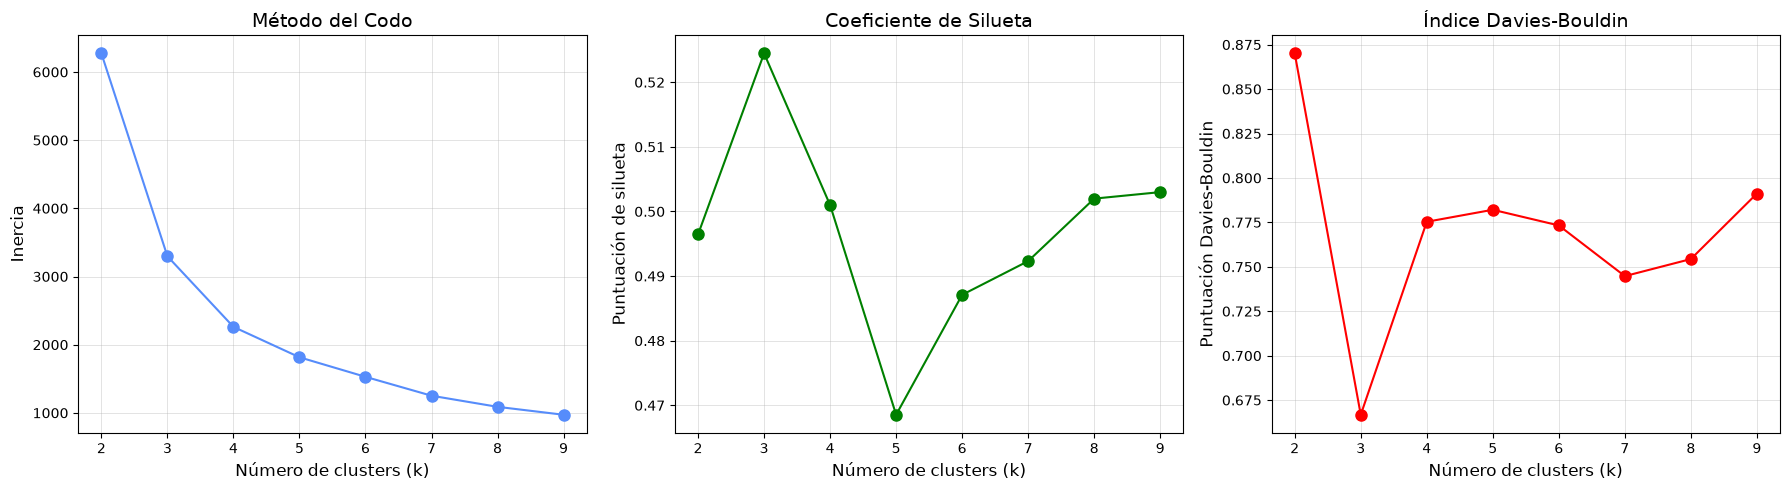

In [13]:
# 4. Visualizar los resultados
# -----------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Gráfico del método del codo
axes[0].plot(k_range, inercias, 'o-', markersize=8)
axes[0].set_title('Método del Codo', fontsize=14)
axes[0].set_xlabel('Número de clusters (k)', fontsize=12)
axes[0].set_ylabel('Inercia', fontsize=12)
axes[0].grid(True)

# Gráfico del coeficiente de silueta
axes[1].plot(k_range, silhouette_scores, 'o-', markersize=8, color='green')
axes[1].set_title('Coeficiente de Silueta', fontsize=14)
axes[1].set_xlabel('Número de clusters (k)', fontsize=12)
axes[1].set_ylabel('Puntuación de silueta', fontsize=12)
axes[1].grid(True)

# Gráfico del índice Davies-Bouldin
axes[2].plot(k_range, davies_bouldin_scores, 'o-', markersize=8, color='red')
axes[2].set_title('Índice Davies-Bouldin', fontsize=14)
axes[2].set_xlabel('Número de clusters (k)', fontsize=12)
axes[2].set_ylabel('Puntuación Davies-Bouldin', fontsize=12)
axes[2].grid(True)

plt.tight_layout()
plt.show()

Como podemos ver en la grafica el mejor valor es el de k=3.

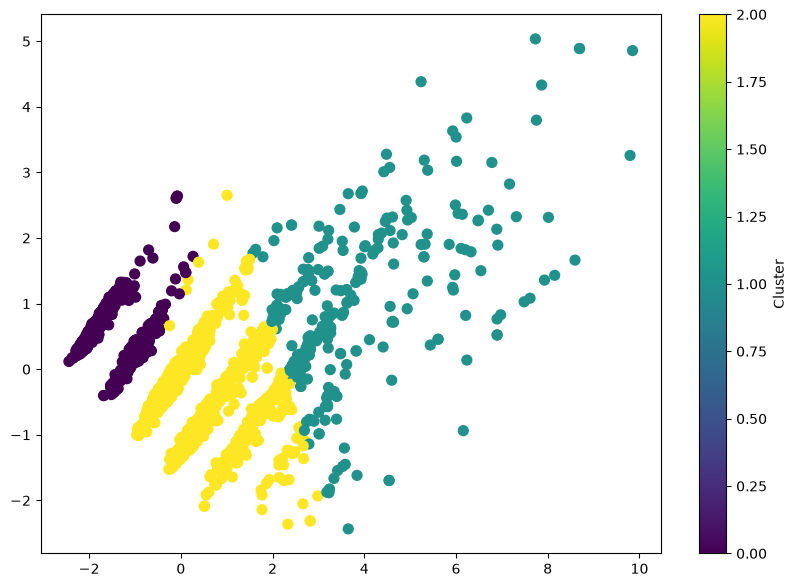

In [14]:
optimal_k = 3
kmeans_optimal = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
cluster_labels = kmeans_optimal.fit_predict(X_pca)

plt.figure(figsize=(10, 7))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_labels, s=50, cmap='viridis')
plt.colorbar(scatter, label='Cluster')

Podemos apreciar a nuestros 3 clusters en la grafica, la separacion no es tan clara, sin embargo, es la que mejor se ajusta.

In [15]:
data_copia = data.copy()

data_copia['lima_top'] = np.where(data['distrito'].isin(['miraflores','san-isidro','barranco']),1,0)
data_copia['cluster'] = cluster_labels

descriptivos = ['median','mean','std',]
columnas = ['dormitorios','banos','area','precio']
agg_ = {"lima_top":["count","mean"]}
agg_.update({i:descriptivos for i in columnas})
lima_top_promedio = np.mean(data_copia['lima_top'].mean().round(2))
print(f"% de departamentos pertenecientes a lima top {lima_top_promedio*100:.2f}%")
data_copia.groupby("cluster").agg(agg_).T.round(2)

% de departamentos pertenecientes a lima top 31.00%


cluster                   0        1        2
lima_top    count   1160.00   269.00  1847.00
            mean       0.33     0.59     0.26
dormitorios median     1.00     3.00     3.00
            mean       1.25     3.22     2.62
            std        0.43     0.58     0.54
banos       median     1.00     3.00     2.00
            mean       1.06     3.06     2.14
            std        0.24     0.78     0.46
area        median    50.00   216.00    89.00
            mean      56.01   237.97    94.27
            std       18.49    79.59    31.52
precio      median  2045.00  7480.00  2700.00
            mean    2098.43  8140.59  2863.97
            std      771.17  3078.34  1173.16

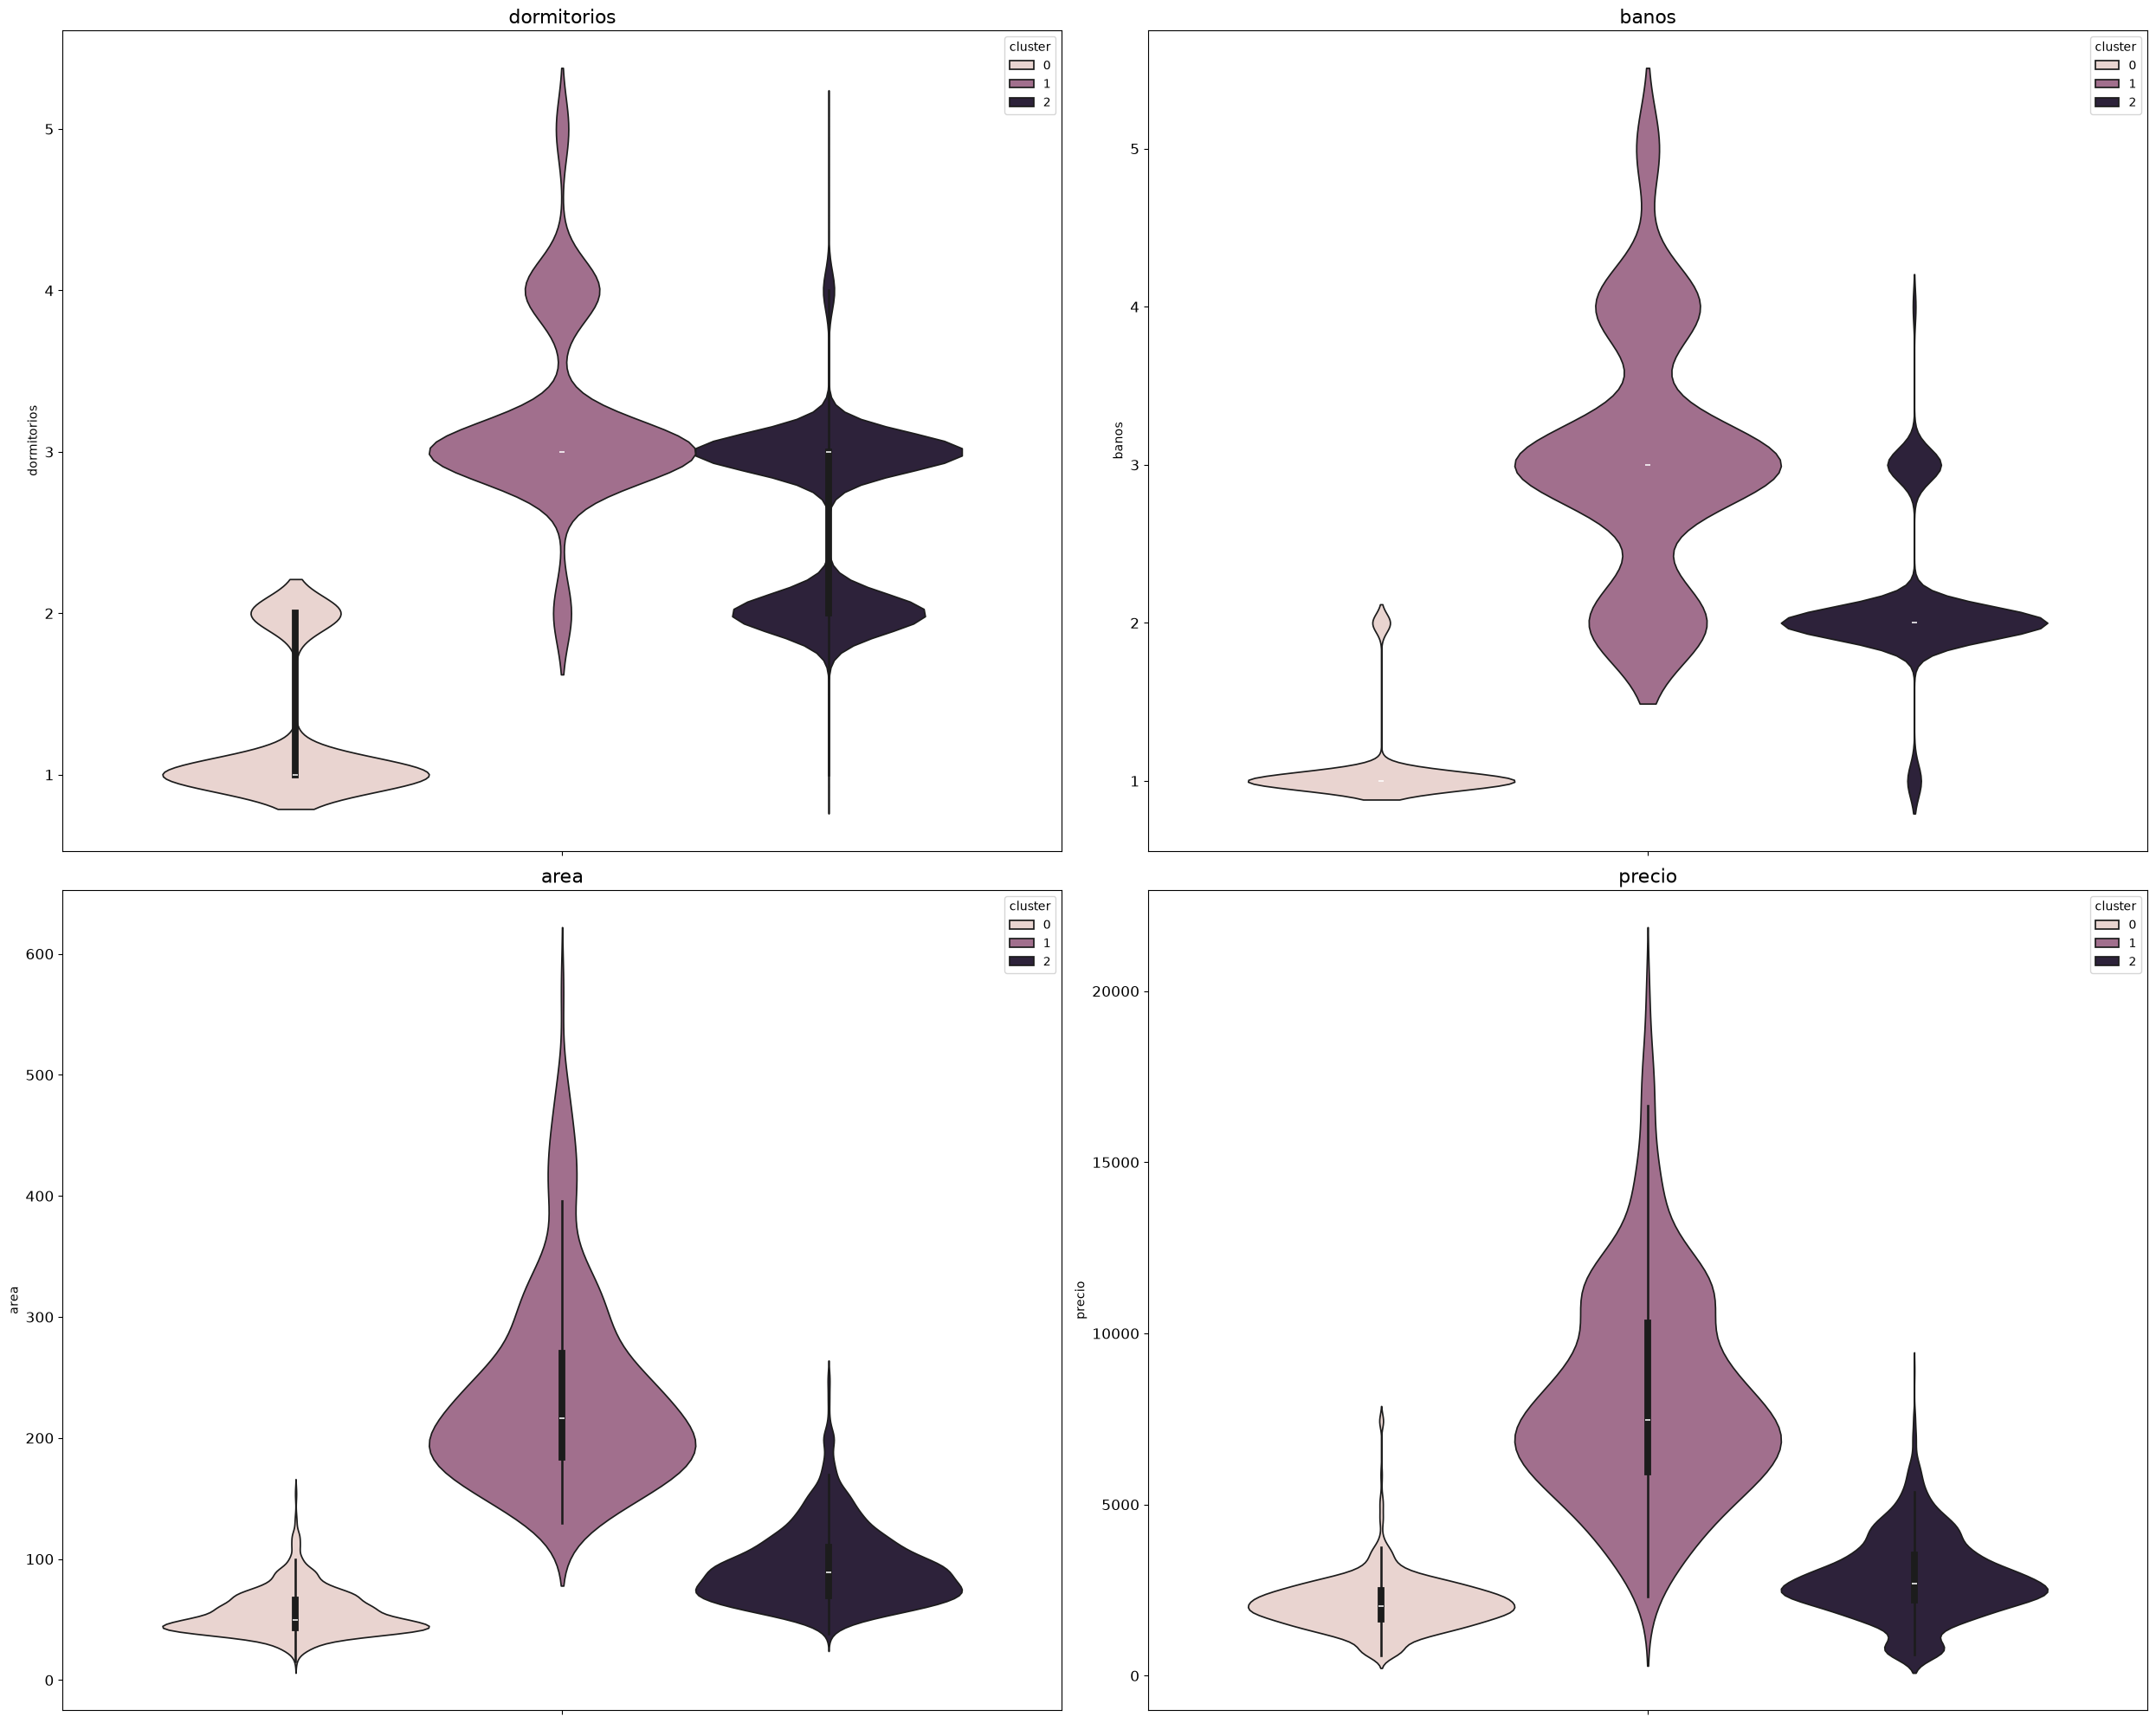

In [17]:
fig, ax = plt.subplots(2, 2, figsize=(25, 20))

for i, col in enumerate(columnas):
    f, c = i//2, i%2
    sns.violinplot(data=data_copia,y=col,hue='cluster',ax=ax[f, c])
    ax[f][c].set_title(col, fontsize=16)
    ax[f][c].tick_params(axis='both', labelsize=12)

# Mejorar espacio entre gráficos
plt.tight_layout()
plt.show()

- 
- **cluster 0** : Este cluster contiene **departamentos pequeños** que son perfectos para una persona o una pareja sin hijos, ya que mayormente poseen **1 dormitorio**, **1 baño**, un area promedio entre **40m2 y 60 m2**, su precio se encuentra entorno a los **1500 y 3000 soles soles** en promedio.
- **cluster 1** : Este cluster contiene departamentos de **muy amplios** con areas muy grandes en su mayoria(**mayor a 200m2**), **3 o 4 dormitorios** en su mayoria, **3 o 4 baños** en su mayoria y un rango de precios bastante amplio que oscila entre los **4000 soles y 11000 soles** en promedio. El % de departamentos "lima_top" es casi el doble en este cluster, esto se da porque los departamentos lujosos presentes en estos distritos suelen ser amplios.
- **cluster 2** : Este cluster contiene **departamentos más "normales"** con un área decente entre **60m2 y 90m2** en promedio, entre **2 y 3 dormitorios**, **2 y 3 baños** y un precio promedio entre **2000 y 4000 soles**.

### 1. Analisis Univariado

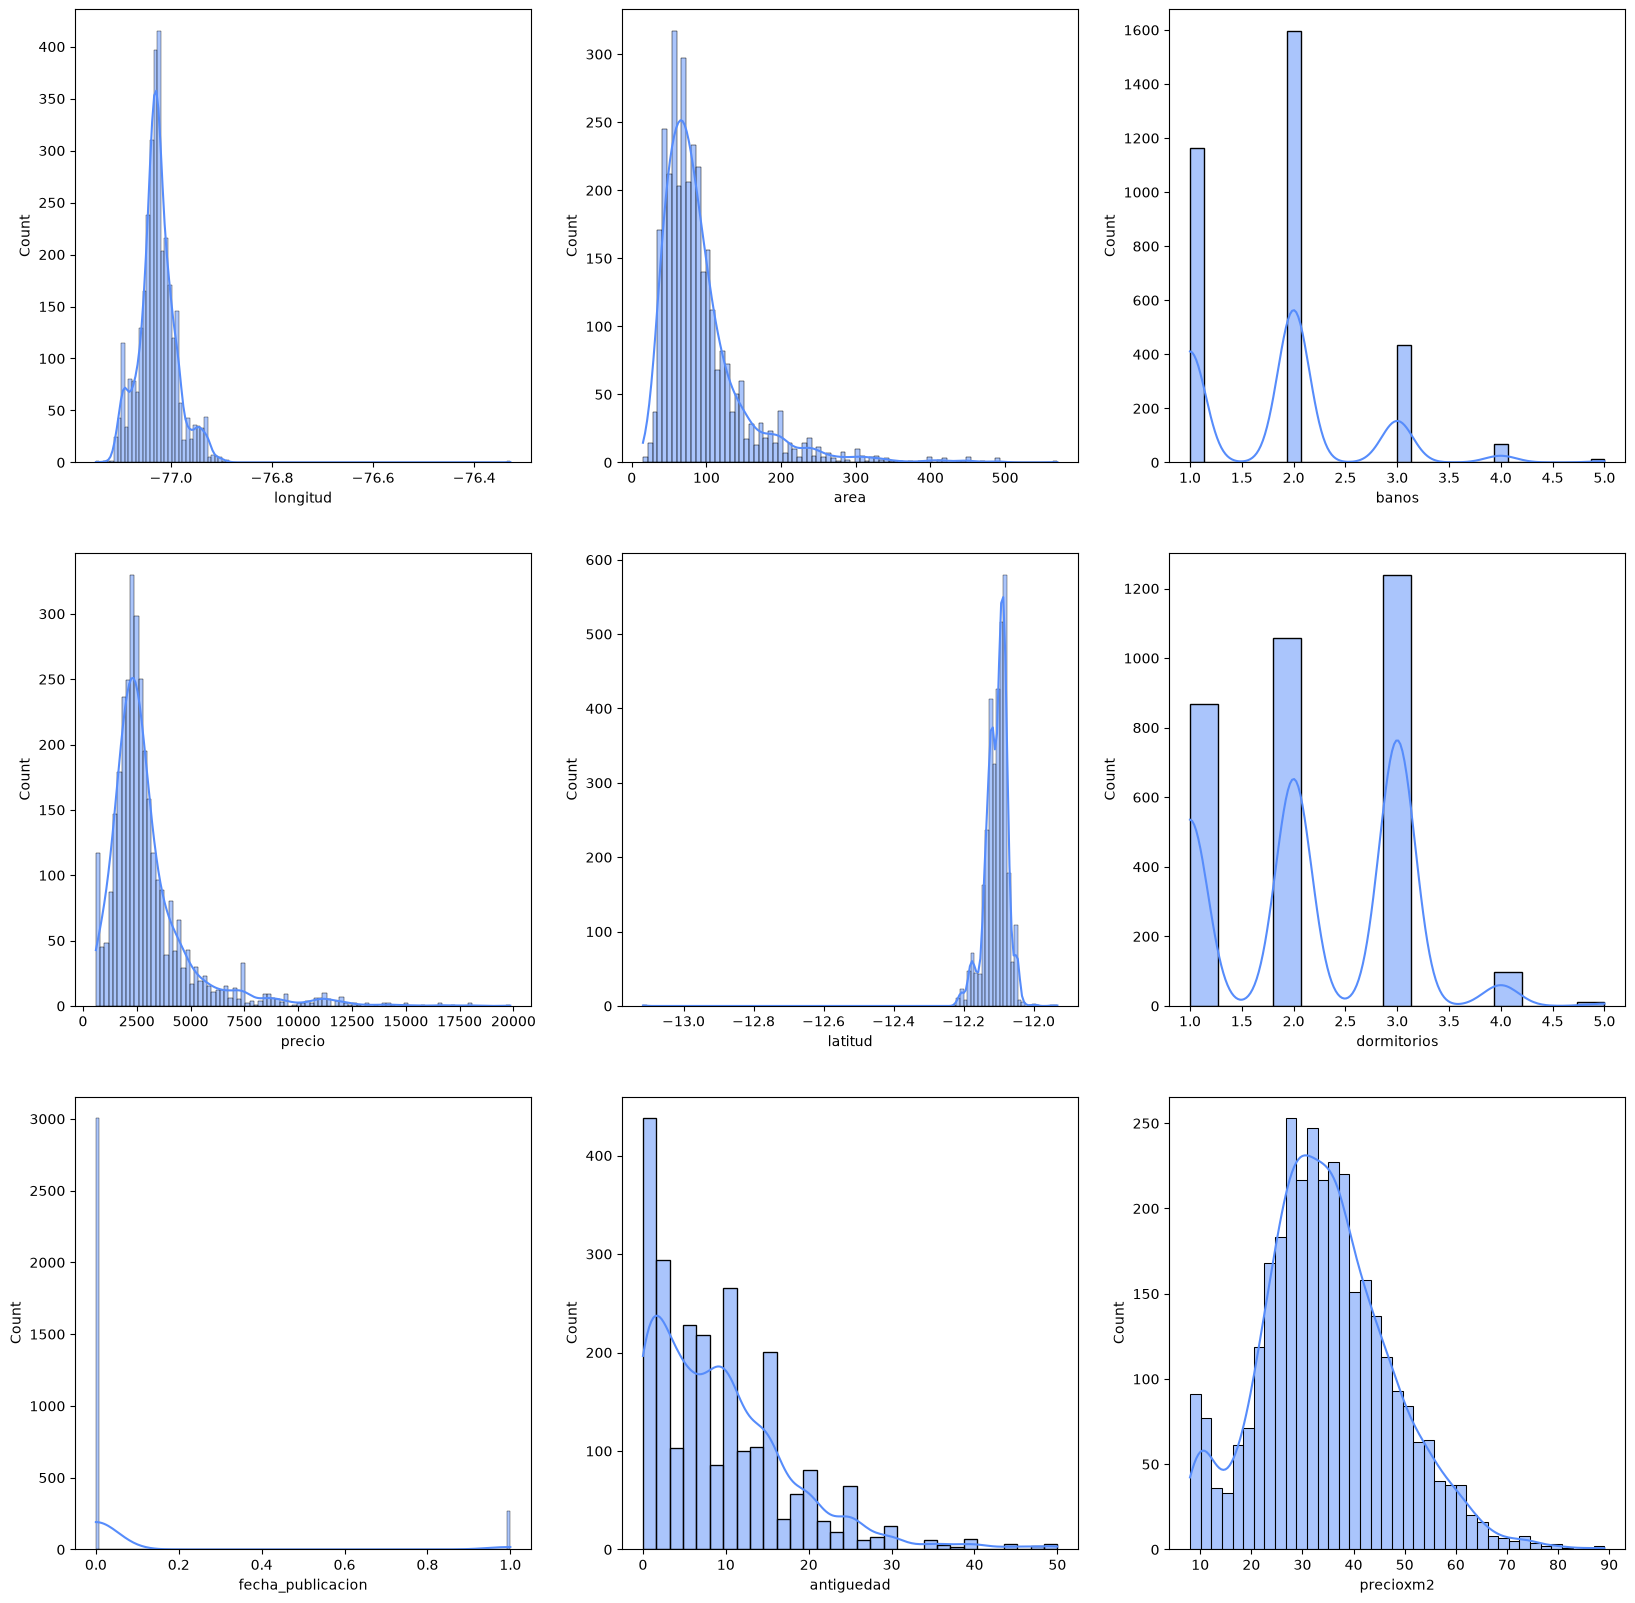

In [18]:
columnas_num = data.select_dtypes(include=['float','int']).columns
fig,ax = plt.subplots(3,3,figsize=(20,20))
for i, column in enumerate(columnas_num):
    sns.histplot(data[column], kde=True, ax=ax[i//3,i%3])
fig.show()

 A partir de las distribuciones anteriores podemos concluir

- **fecha_publicación**: Las publicaciones de este mes son considerablemente mayores a las publicaciones del mes pasado.
- **latitud**: La latitud muestra una distribución sesgada(-) con varios picos, esto puede indicar las concentraciones existentes en los diferentes distritos.
- **longitud**: La longitud muestra una distribución un poco menos sesgada(-) y con picos no tan pronunciados como la latitud.
- **dormitorios**: Se puede ver que la mayoria de departamentos poseen 2 o 3 dormitorios.
- **banos**: Se puede apreciar que la mayoria de los departamentos poseen 1 o 2 dormitorios.  
- **area**: Se puede ver que el area muestra una distribucion fuertemente sesgada(+).
- **precio**: El precio al igual que el area muestra una distribucion fuertemente sesgada(+).
- **precioxm2**: El precioxm2 muestra una distribucion ligeramente sesgada(+),

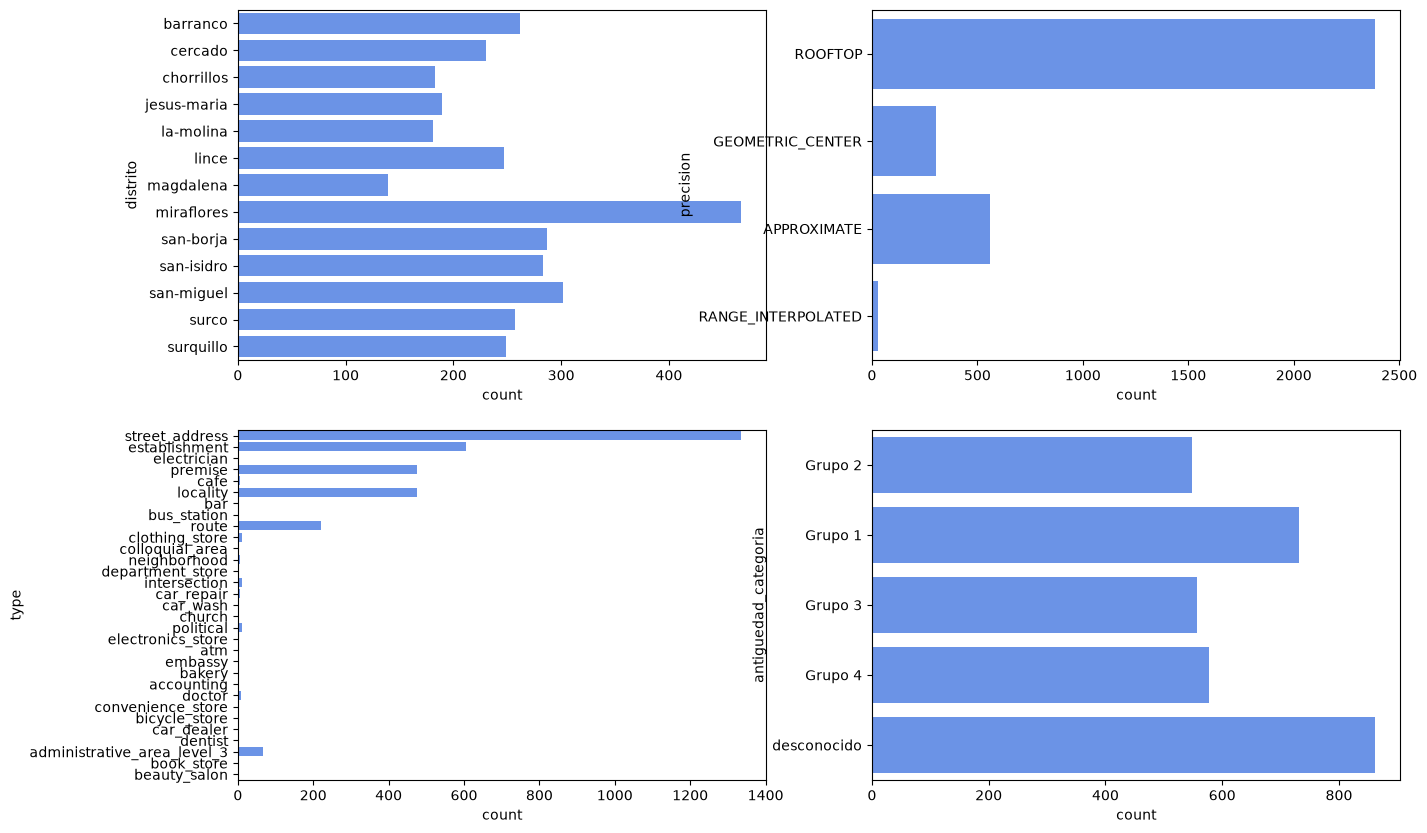

In [19]:
columnas_obj = ['distrito','precision','type','antiguedad_categoria']
fig,ax = plt.subplots(2,2,figsize=(15,10))
for i, column in enumerate(columnas_obj):
    sns.countplot(y=data[column],ax=ax[i//2,i%2])
fig.show()

### 2. Analisis de la correlacion

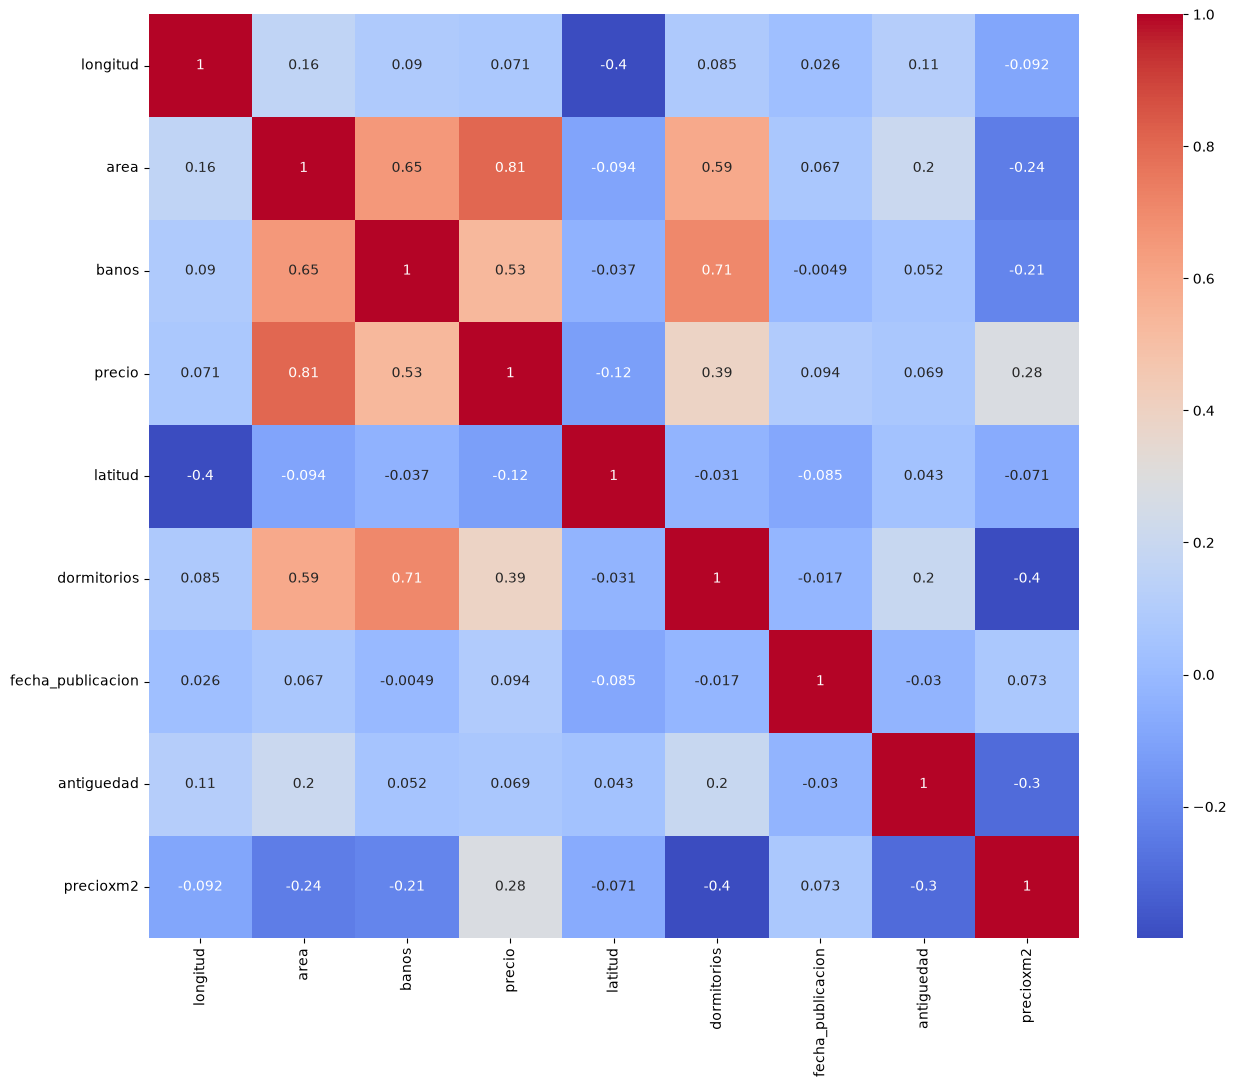

In [20]:
correlacion = data.select_dtypes(include=['float','int']).corr()
plt.figure(figsize=(15,12))
sns.heatmap(correlacion, annot=True, cmap='coolwarm')
plt.show()

### 3. Analisis Multivariado

In [21]:
visualizacion_df = data.copy()
visualizacion_df['lima_top'] = np.where(data['distrito'].isin(['miraflores','san-isidro','barranco','lince']),1,0)
visualizacion_df['dorm+ban'] = data['dormitorios'] + data['banos']
data['banos/dormitorio'] = data['banos']/data['dormitorios']
visualizacion_df['banos/dormitorio>=1'] = np.where(data['banos/dormitorio']>=1,1,0)
visualizacion_df['banosxdormitorio_cat'] = np.where(data['banos/dormitorio']<1,"<1",
                                              np.where(data['banos/dormitorio']==1,"==1",">1"))

visualizacion_df['distrito_clase'] =  visualizacion_df['distrito'].map({
    "miraflores":"clase1",
    "san-isidro":"clase1",
    "barranco":"clase1",
    "lince":"clase1",
    "magdalena":"clase2",
    "surquillo":"clase2",
    "jesus-maria":"clase2",
    "san-borja":"clase2",
    "surco":"clase2",
    "cercado":"clase3",
    "san-miguel":"clase3",
    "chorrillos":"clase3",
    "la-molina":"clase3"
})


**2.1. Precio vs Area**

Relacion entre el precio y el area de un departamento.
 

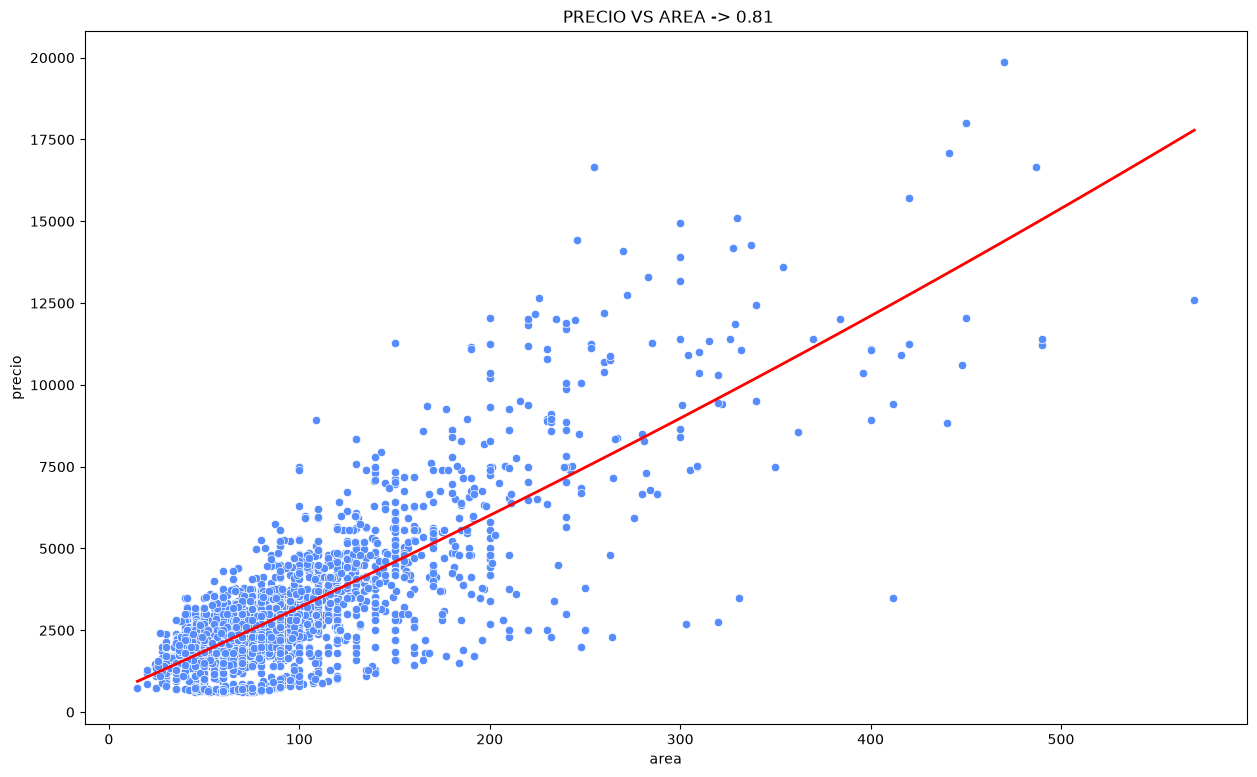

In [22]:
poly = PolynomialFeatures(degree=2)
X = visualizacion_df[['area']]
y = visualizacion_df['precio']
X_poly = poly.fit_transform(X)

modelo = LinearRegression()
modelo.fit(X_poly,y)

X_range = np.linspace(X.min(),X.max(),100).reshape(-1,1)
X_range_poly = poly.transform(X_range)
y_pred = modelo.predict(X_range_poly)

corr = visualizacion_df[['precio','area']].corr().values[0][1].round(2)
plt.figure(figsize=(15,9))
sns.scatterplot(data=visualizacion_df,x='area',y='precio')
plt.plot(X_range, y_pred, color='red', label="Ajuste Polinómico (Grado 2)", linewidth=2)
plt.title(f" PRECIO VS AREA -> {corr}")
plt.show()

Conclusión:
- Se puede apreciar una correlación alta y una **tendencia lineal positiva.**
- Podemos ver que el precio tiene una correlación alta de 0.83 con el área, sin embargo, también se observa una ligera tendencia logarítmica, lo que sugiere que, a partir de un cierto tamaño, el incremento en el precio se desacelera y deja de crecer de manera proporcional al aumento del área, hay que considerar que aqui entran otros factores en juego como el distrito, dormitorios, etc.

**2.2. Precio vs Area vs Distrito**

Relacion del precio y el area de los departamentos de un distrito.

In [23]:
visualizacion_df.groupby('distrito')['precioxm2'].describe().sort_values(by='mean',ascending=False)

,count,mean,std,min,25%,50%,75%,max
distrito,,,,,,,,
barranco,262.0,45.712344,11.598193,19.886364,38.352410,44.693822,53.488372,79.666667
miraflores,467.0,41.513762,10.363148,20.000000,33.878333,39.750000,46.825000,77.682927
san-isidro,283.0,39.820351,15.790099,8.035714,31.995455,38.938053,48.841071,80.000000
lince,247.0,37.449901,14.509467,8.315068,28.333333,37.735849,46.608333,89.074074
jesus-maria,189.0,32.893475,11.194521,8.518987,26.153846,33.333333,39.666667,61.342105
surquillo,249.0,32.478043,12.120631,8.000000,25.324675,33.846154,40.762712,60.526316
magdalena,139.0,32.463522,12.381300,8.376471,27.005747,33.673469,41.027518,69.550000
surco,257.0,31.747213,10.034625,8.035714,25.000000,31.034483,36.428571,60.975610
san-miguel,302.0,30.907318,8.264362,16.000000,25.075301,30.128205,35.555556,60.833333


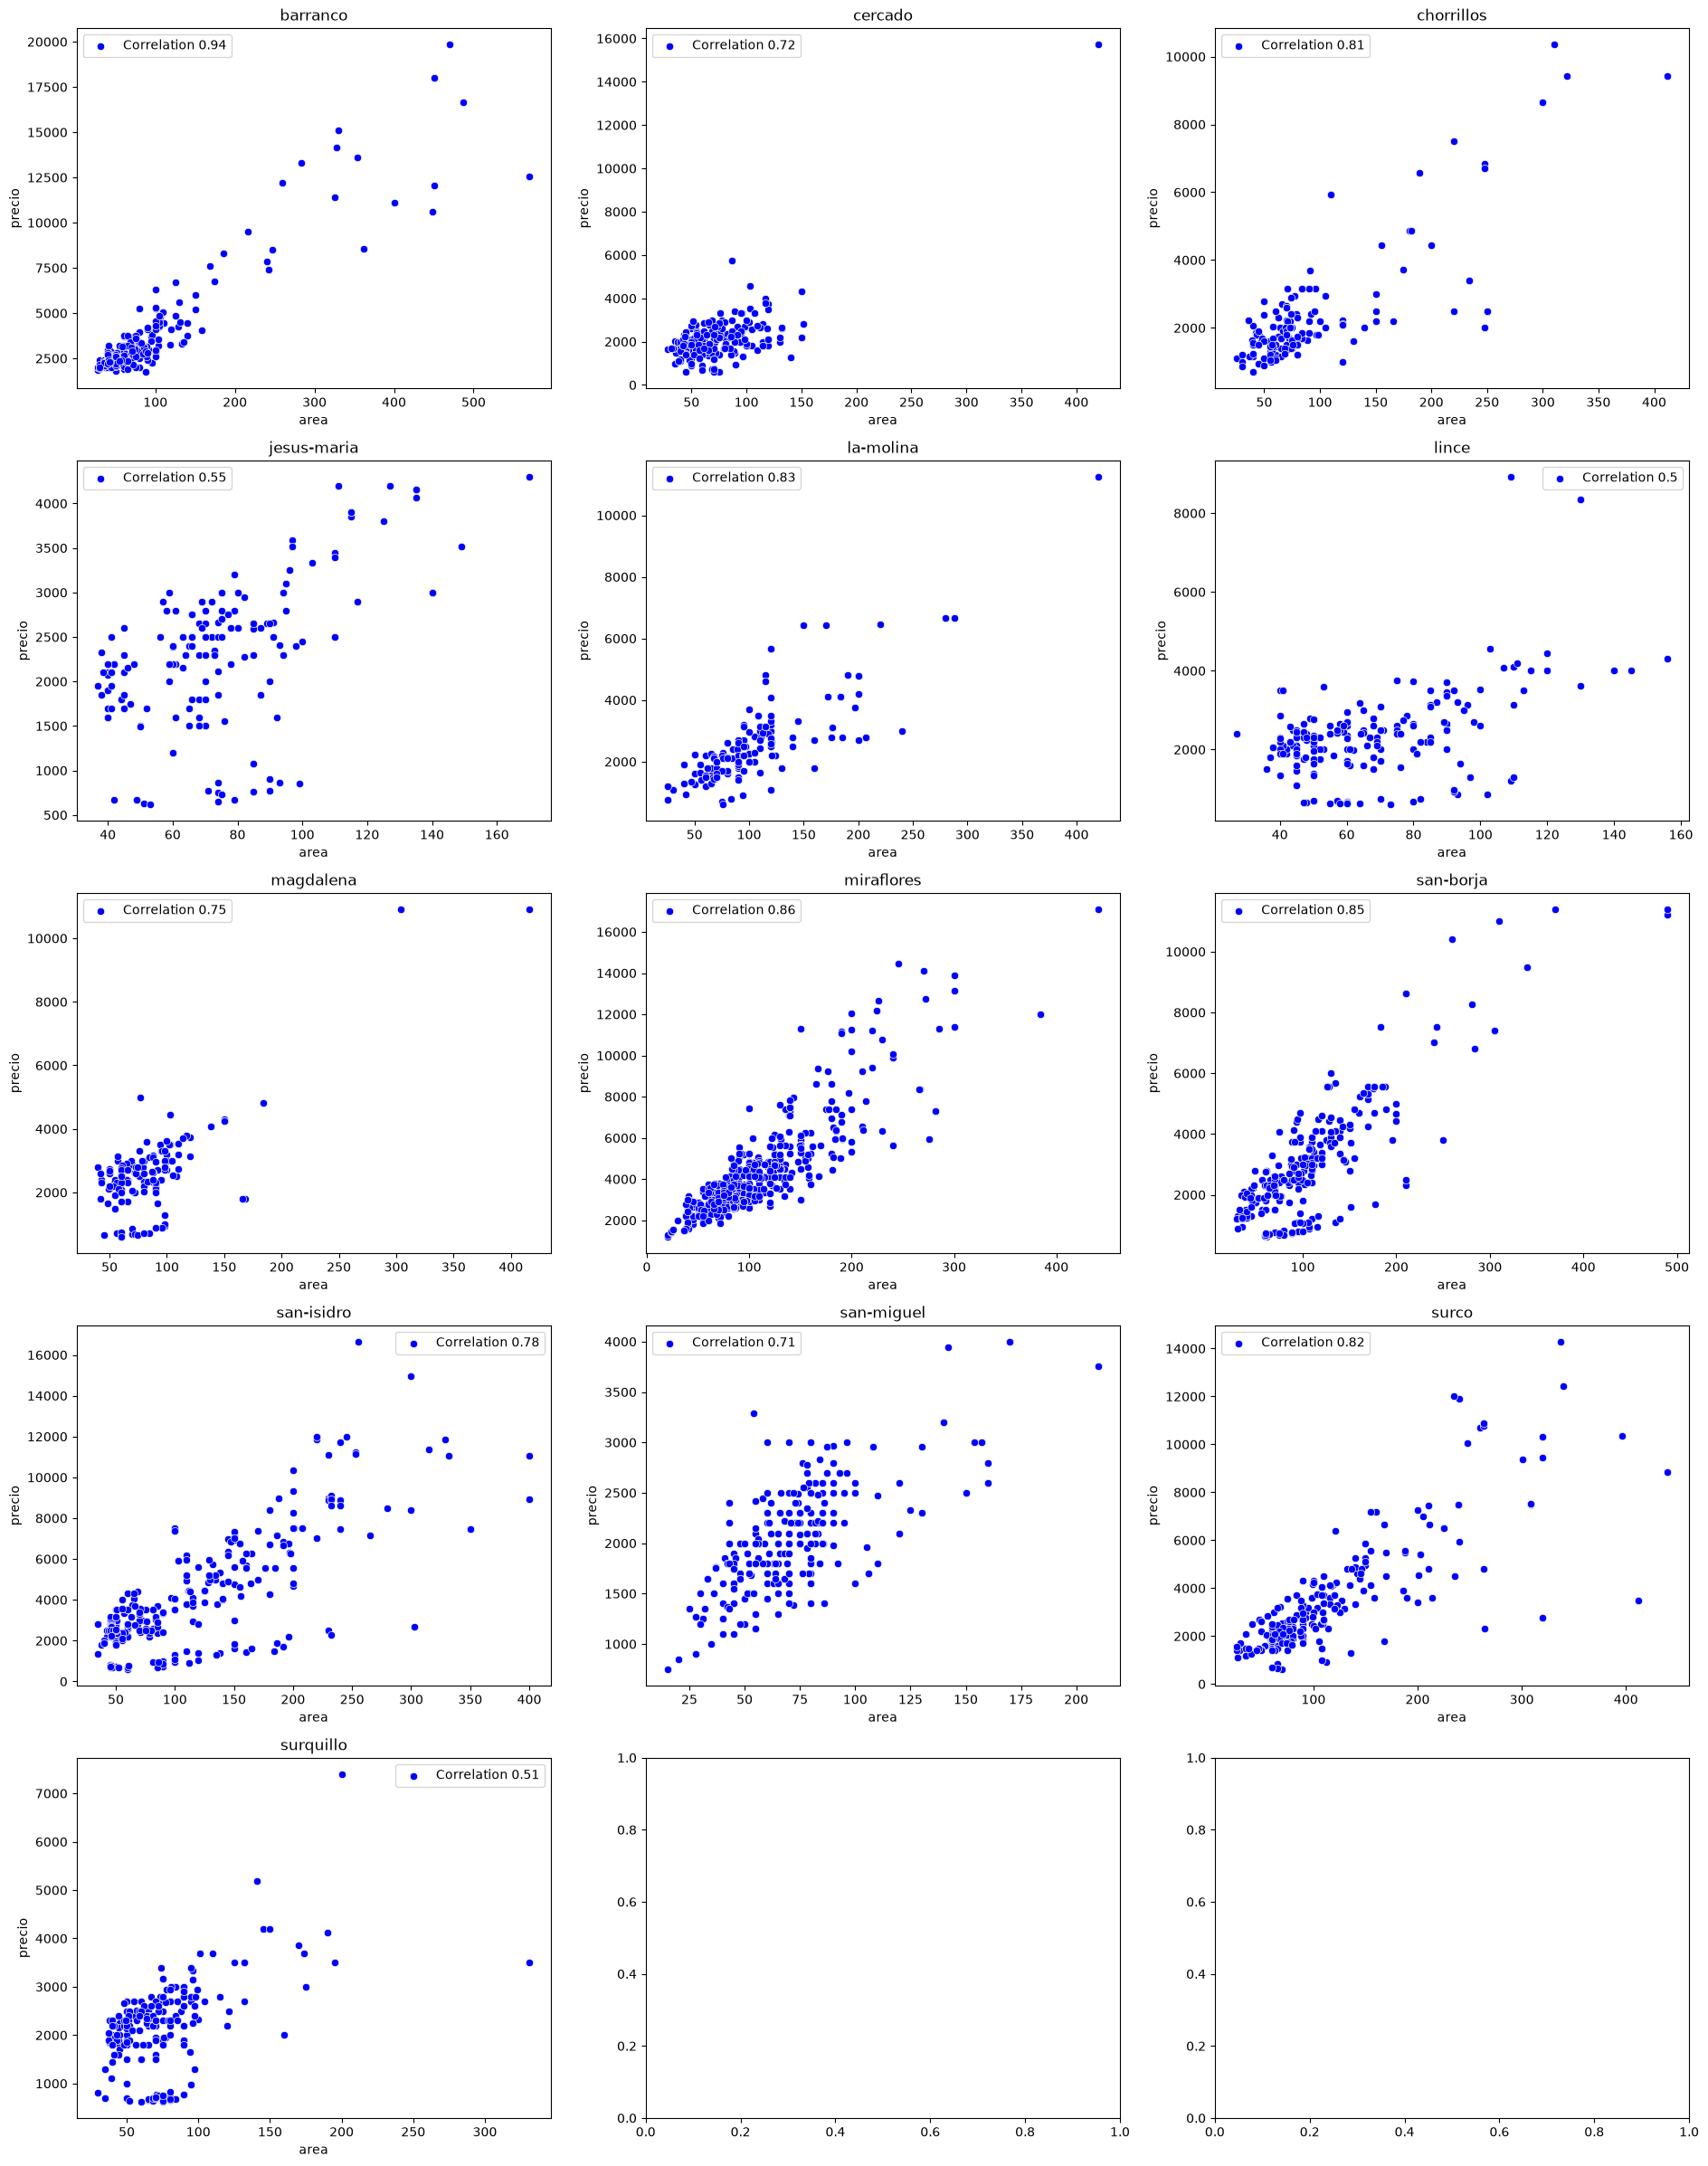

In [24]:
fig,ax = plt.subplots(5,3,figsize=(23,30))
distritos = visualizacion_df['distrito'].unique()

for i,distrito in enumerate(distritos):
    f,c = i//3,i%3
    data_distrito = visualizacion_df.query(f"distrito=='{distrito}'")
    corr_distrito = data_distrito[['precio','area']].corr().values[0][1].round(2)
    sns.scatterplot(data=data_distrito,x='area',y='precio',color='blue',ax=ax[f,c],label=f"Correlation {corr_distrito}")
    ax[f,c].set_title(f"{distrito}")
fig.show()

Conclusión:

- Se puede apreciar una **correlación alta** en los **distritos más uniformes** (que solo tienen un tipo de zonas) que en los **distritos menos uniformes** (que tienen zonas malas y buenas). En los distritos de Lima Top, se puede ver que la correlación entre el precio y el área es notable (mayor a 0.80), aquí incluimos a Barranco, Miraflores, San Isidro, Surco, San Borja, Magdalena y Chorrillos, esto indica que son distritos uniformes **(en cuanto a departamentos en alquiler)** por lo que la relación área vs precio se mantiene proporcional en la mayoría de los departamentos lo cual hace a su vez una variable muy importante para poder calcular el precio de un departamento en estos distritos, en otros distritos como Lince, Cercado o Jesus Maria las correlaciones no son tan grandes esto indica que tienen zonas más variadas, algunas mejores, otras peores, por lo que el área puede no ayudar tanto a determinar el precio de estos departamentos.

**2.3. Precioxm2 vs lima_top**

Relación del precio de cada m2 entre los departamentos pertenecientes a lima-top y los que no pertenecen a lima-top.

- Cual es el promedio de los departamentos pertenecientes a los distritos 'lima-top' y los que no pertenecen a 'lima-top'?
- La diferencia en el precioxm2 de los departamentos pertencientes a estas 2 clases de distritos es significativa?

In [25]:
visualizacion_df.groupby("lima_top")['precio'].describe().T

lima_top,0,1
count,2017.000000,1259.000000
mean,2535.896182,3811.639396
std,1531.049154,2500.486122
min,600.000000,600.000000
25%,1700.000000,2400.000000
50%,2230.000000,3000.000000
75%,2800.000000,4440.000000
max,15725.000000,19855.000000


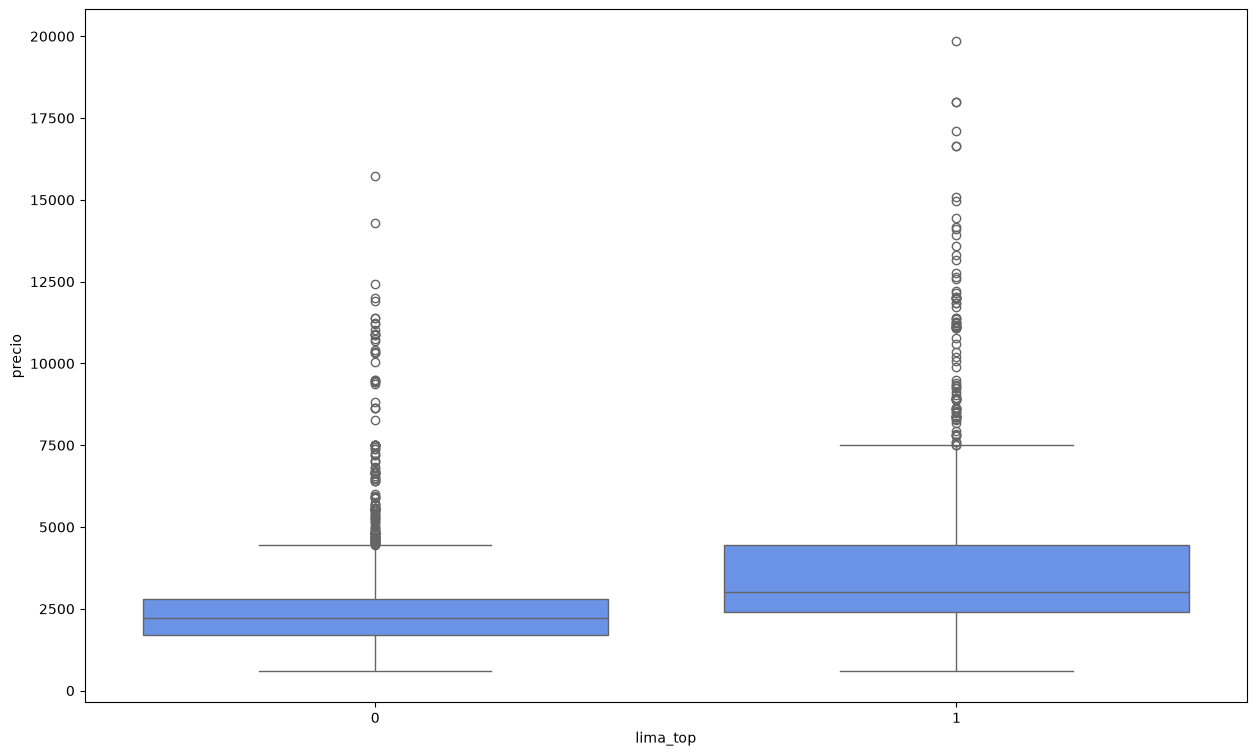

In [26]:
plt.figure(figsize=(15,9))
sns.boxplot(data=visualizacion_df,x='lima_top',y='precio')
plt.show()

Observaciones:
 
- Se puede apreciar que los departamentos en **lima_top** tienen en promedio un precio **considerablemente mayor** a los departamentos que no se encuentran en lima_top. 

- **Hipotesis: Son los precios de los departamentos de lima_top más caros en promedio que los departamentos que no son de lima_top?**

**2.4. Precioxm2 vs distrito**

Relación del precio de cada m2 en los diferentes distritos de Lima.

- Como varia el precio de cada m2 en los diferentes distritos de Lima?
- Los distritos ...?

In [27]:
distritos_ordenados = visualizacion_df.groupby('distrito')['precioxm2'].mean().sort_values(ascending=False)

In [28]:
visualizacion_df.groupby("distrito")['precioxm2'].describe().sort_values(by='mean', ascending=False)

,count,mean,std,min,25%,50%,75%,max
distrito,,,,,,,,
barranco,262.0,45.712344,11.598193,19.886364,38.352410,44.693822,53.488372,79.666667
miraflores,467.0,41.513762,10.363148,20.000000,33.878333,39.750000,46.825000,77.682927
san-isidro,283.0,39.820351,15.790099,8.035714,31.995455,38.938053,48.841071,80.000000
lince,247.0,37.449901,14.509467,8.315068,28.333333,37.735849,46.608333,89.074074
jesus-maria,189.0,32.893475,11.194521,8.518987,26.153846,33.333333,39.666667,61.342105
surquillo,249.0,32.478043,12.120631,8.000000,25.324675,33.846154,40.762712,60.526316
magdalena,139.0,32.463522,12.381300,8.376471,27.005747,33.673469,41.027518,69.550000
surco,257.0,31.747213,10.034625,8.035714,25.000000,31.034483,36.428571,60.975610
san-miguel,302.0,30.907318,8.264362,16.000000,25.075301,30.128205,35.555556,60.833333


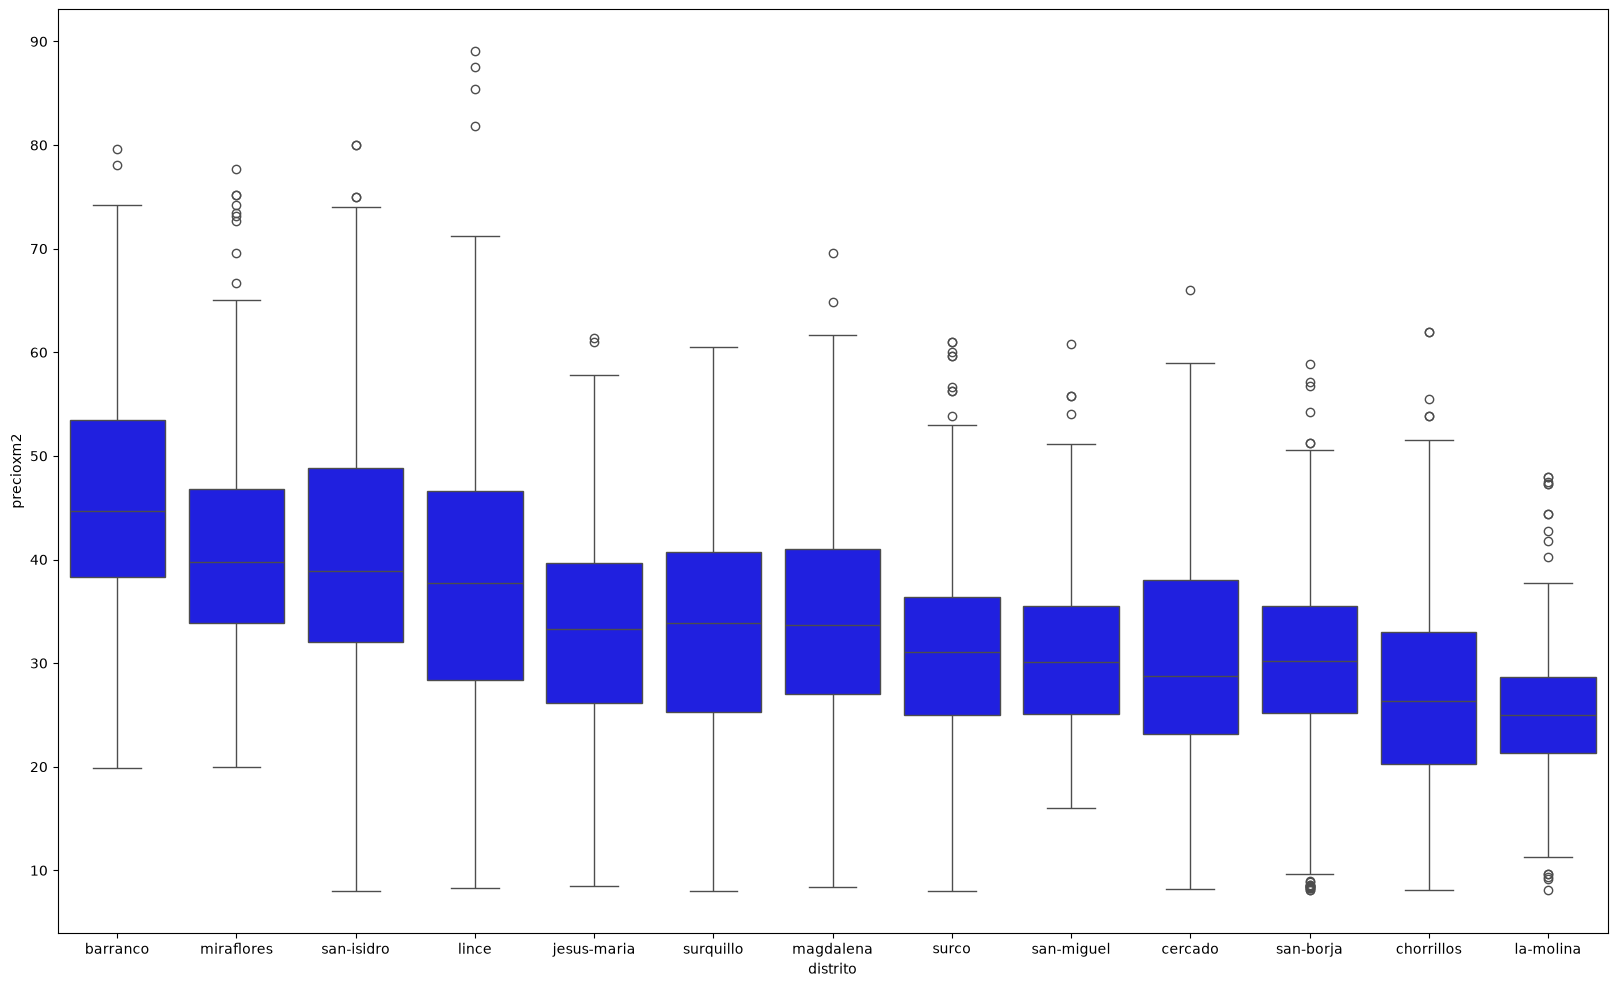

In [29]:
plt.figure(figsize=(20,12))
sns.boxplot(data=visualizacion_df,x='distrito',y='precioxm2',color='blue',order=distritos_ordenados.index)
plt.show()

Observaciones:

- En las tres primeras posiciones podemos ver claramente a los distritos de Lima-Top (Barranco, San Isidro y Miraflores), sin embargo, el distrito de Lince tiene una media muy cercana a la de los distritos top y una mediana por encima a la de los distritos de San Isidro y Miraflores, esto podría indicar que este distrito es un nuevo distrito "top" para departamentos en alquiler. Tambien se puede indicar (de manera no exacta y usando la grafica) que en promedio cada m2 cuesta 42 soles en estos distritos.

- En las siguientes 3 posiciones posteriores encontramos a Magdalena, Surquillo y Jesus Maria con un promedio y una mediana bastante similar, como se puede ver en la grafica. Tambien se puede indicar (de manera no exacta y usando la grafica) que en promedio cada m2 cuesta 35 soles en estos distritos.

- En las siguientes 4 posiciones encontramos a San Borja, Surco, Cercado y San Miguel con un promedio y una mediana bastante similar, como se puede ver en la grafica. Tambien se puede indicar (de manera no exacta y usando la grafica) que en promedio cada m2 cuesta 31 soles en estos distritos.

- Por ultimo tenemos a Chorrillos y La Molina con un promedio y una mediana similar, en estos distritos podemos indicar que el precio de cada m2 cuesta  27 soles en promedio.
- **Hipotesis: ..........**

**2.5. Precio vs antiguedad**

Relacion entre la antiguedad de un departamento y su precio.

- Como afecta la antiguedad al precio de un departamento?
- El precio disminuye con la antiguedad?

In [30]:
antiguedad_ordenada = [f"Grupo {i+1}" for i in range(4)] + ["desconocido"]

In [31]:
visualizacion_df.groupby('antiguedad_categoria')['precio'].describe()

,count,mean,std,min,25%,50%,75%,max
antiguedad_categoria,,,,,,,,
Grupo 1,732.0,2922.163661,1707.327727,607.0,2062.0,2500.0,3200.0,18000.0
Grupo 2,549.0,3170.749909,1941.111181,600.0,2120.0,2600.0,3700.0,16650.0
Grupo 3,556.0,3651.478417,2516.993501,673.0,2134.5,2900.0,4125.0,17100.0
Grupo 4,577.0,3339.941941,2337.597630,650.0,2000.0,2700.0,3700.0,19855.0
desconocido,862.0,2409.074942,1659.733199,600.0,1500.0,2114.5,2731.5,15725.0


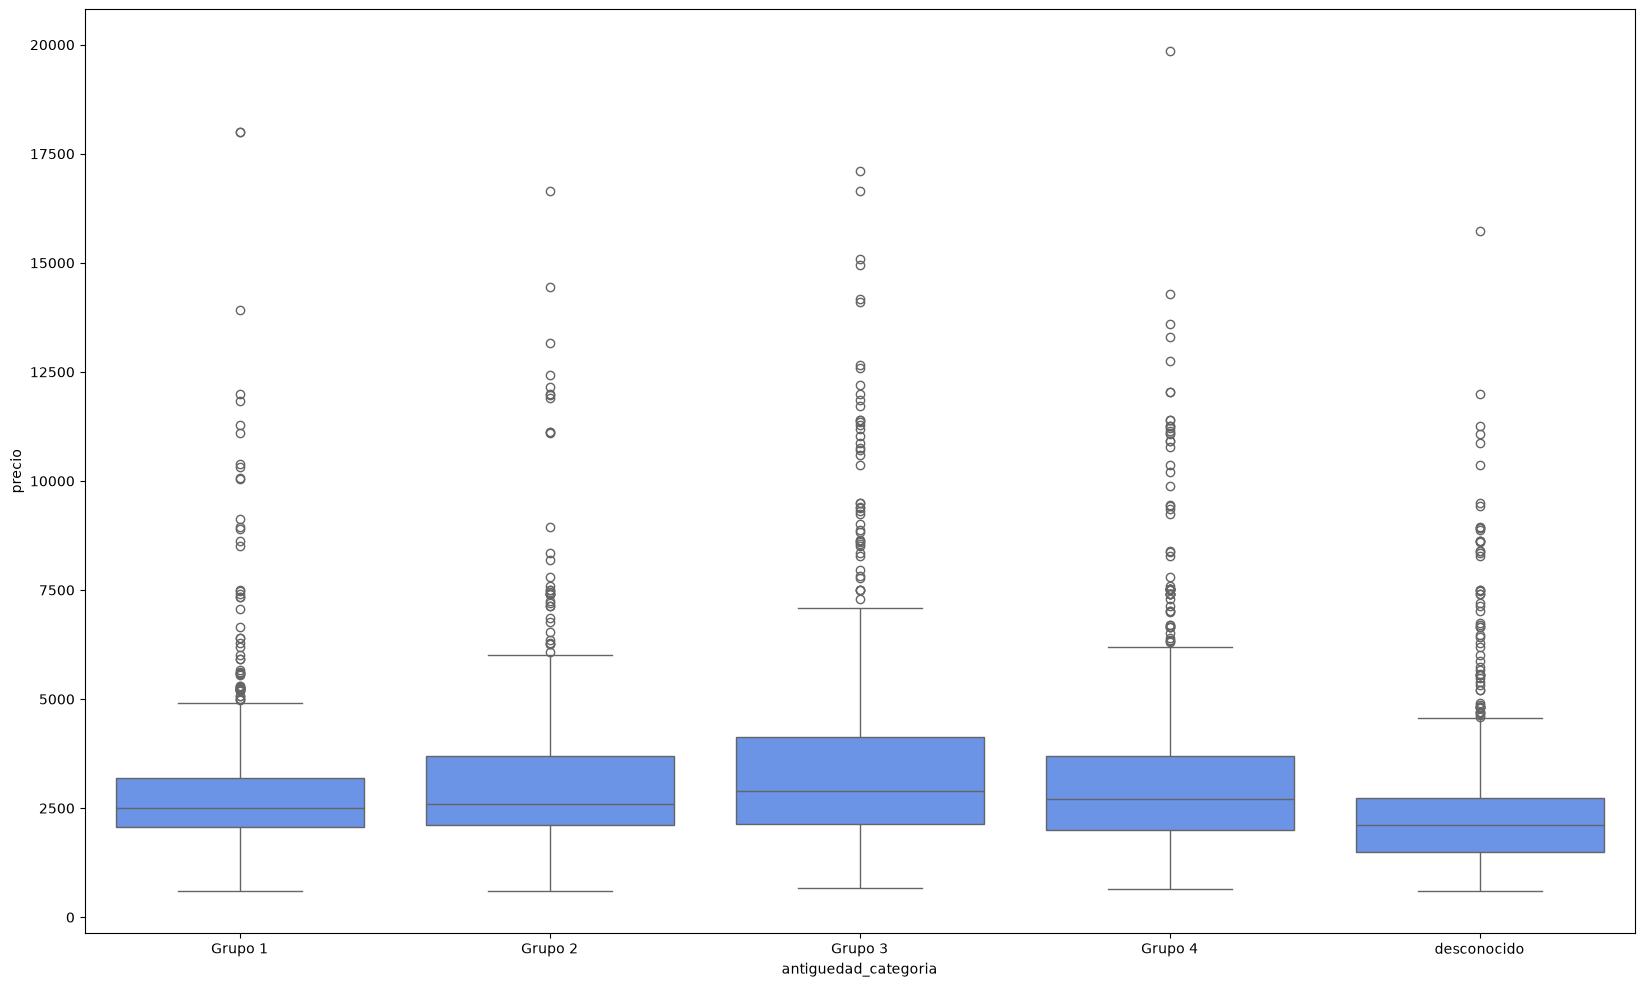

In [32]:
plt.figure(figsize=(20,12))
sns.boxplot(data=visualizacion_df,x='antiguedad_categoria',y='precio',order=antiguedad_ordenada)
plt.show()

Observaciones:

- Se puede apreciar una **tendencia ligeramente al alza**, es decir, a medida que aumenta la antiguedad el precio del departamento es ligeramente mayor o dicho de otro modo a departamentos más recientes el precio es menor. Se esperaría ver una disminución del precio si el departamento es más antiguo, sin embargo, se ve todo lo contrario, los departamentos' más antiguos tienen una media y una mediana superior a la de los departamentos más recientes.
- **Hipotesis : El precio de un departamento no varia considerablemente para departamentos recientes y antiguos**

**2.6 area vs antiguedad**

Relación entre la antiguedad y el área de un departamento. 

- Como afecta la antiguedad al área de un departamento?
- Los departamentos más recientes suelen tener menor area_

In [33]:
visualizacion_df.groupby('antiguedad_categoria')['area'].describe()

,count,mean,std,min,25%,50%,75%,max
antiguedad_categoria,,,,,,,,
Grupo 1,732.0,75.053552,45.057198,20.0,46.00,64.0,84.25,450.0
Grupo 2,549.0,88.409290,47.978074,26.0,56.00,76.0,103.00,412.0
Grupo 3,556.0,113.273615,71.265883,25.0,70.75,93.5,130.00,570.0
Grupo 4,577.0,109.903449,69.643680,20.0,70.00,90.0,120.17,490.0
desconocido,862.0,84.968596,49.587973,15.0,55.00,70.0,97.00,420.0


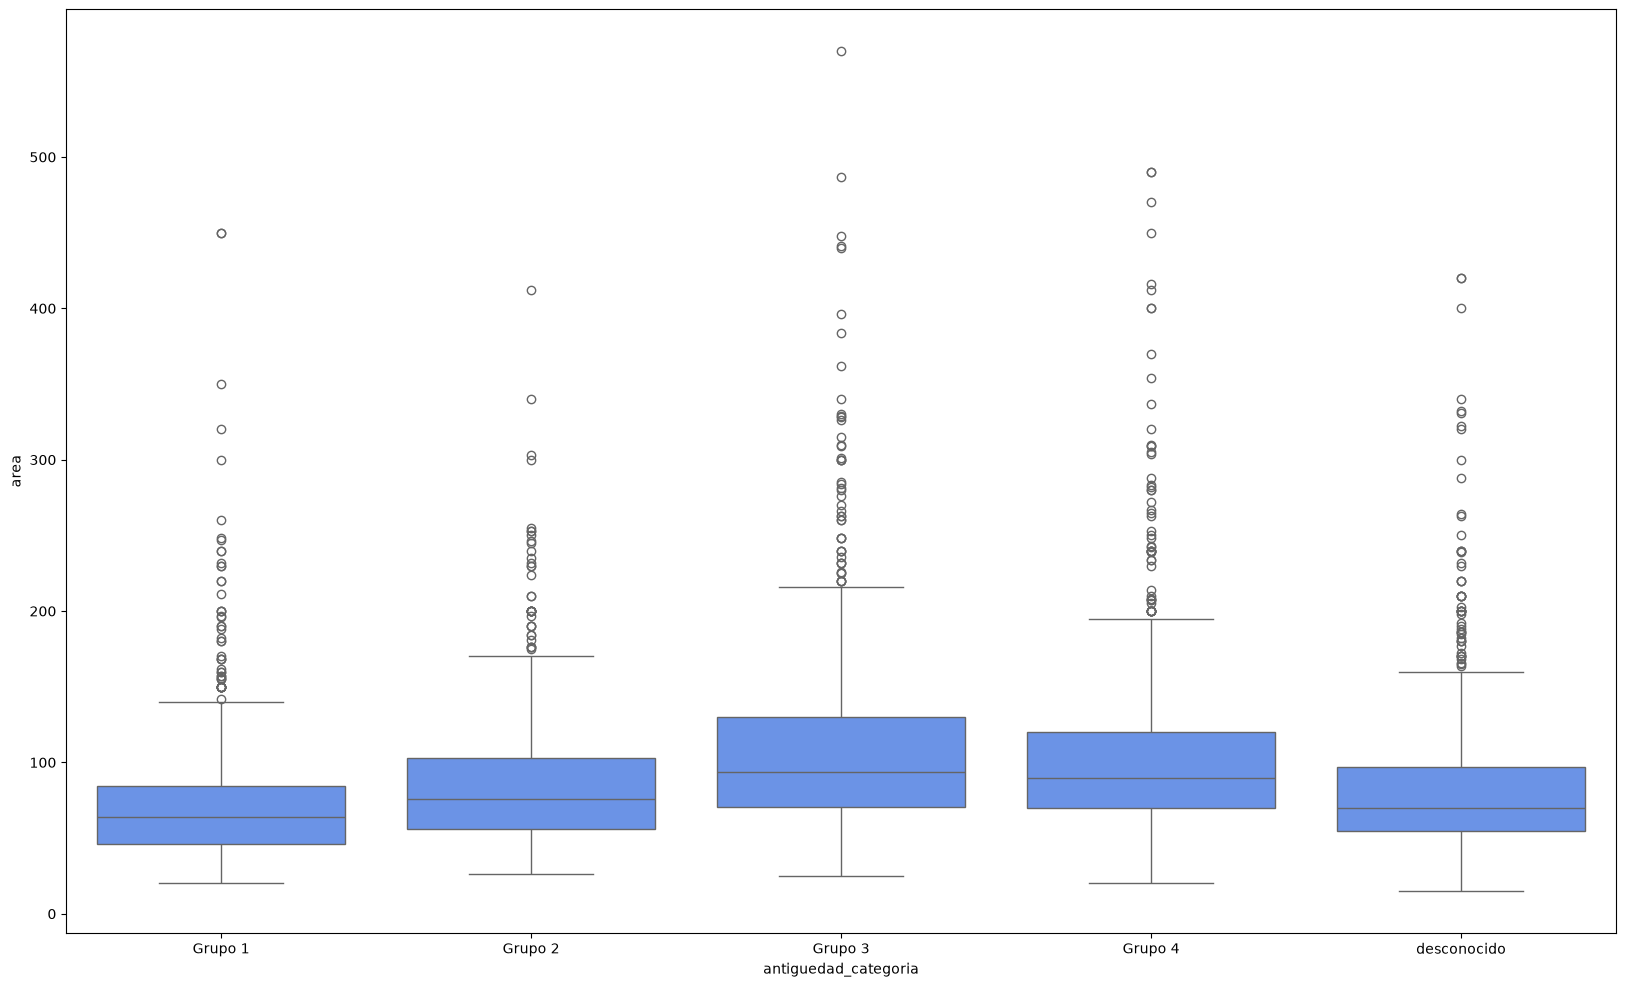

In [34]:
plt.figure(figsize=(20,12))
sns.boxplot(data=visualizacion_df,x='antiguedad_categoria',y='area',order=antiguedad_ordenada)
plt.show()

Observaciones:

- Se puede apreciar una **tendencia al alza**, es decir, a medida que aumente la antiguedad del departamento el área se hace más grande, o dicho de otro modo, los departamentos más antiguos solían tener mayor área, ádemas podemos agregar que el área ha ido disminuyendo aproximadamente en un 30% con el tiempo.
- **Hipotesis: Los departamentos más recientes poseen una menor área que los departamentos más antiguos.**

**2.7. Precioxm2 vs antiguedad**

Relación entre la antiguedad y el área de un departamento. 

- Como afecta la antiguedad al precio de cada m2 de un departamento?
- El precio de cada m2 es mayor para departamentos más recientes?


In [35]:
visualizacion_df.groupby('antiguedad_categoria')['precioxm2'].describe()

,count,mean,std,min,25%,50%,75%,max
antiguedad_categoria,,,,,,,,
Grupo 1,732.0,41.704443,13.330098,8.315068,32.791218,40.357257,50.847823,87.500000
Grupo 2,549.0,37.257769,11.478346,8.376471,29.879518,36.153846,44.444444,74.200000
Grupo 3,556.0,32.833760,9.331491,8.064516,27.142857,31.844805,38.218966,62.900000
Grupo 4,577.0,31.406908,10.020353,8.152174,24.545455,30.263158,37.500000,65.000000
desconocido,862.0,30.291160,13.698868,8.000000,21.748252,29.338547,38.461538,89.074074


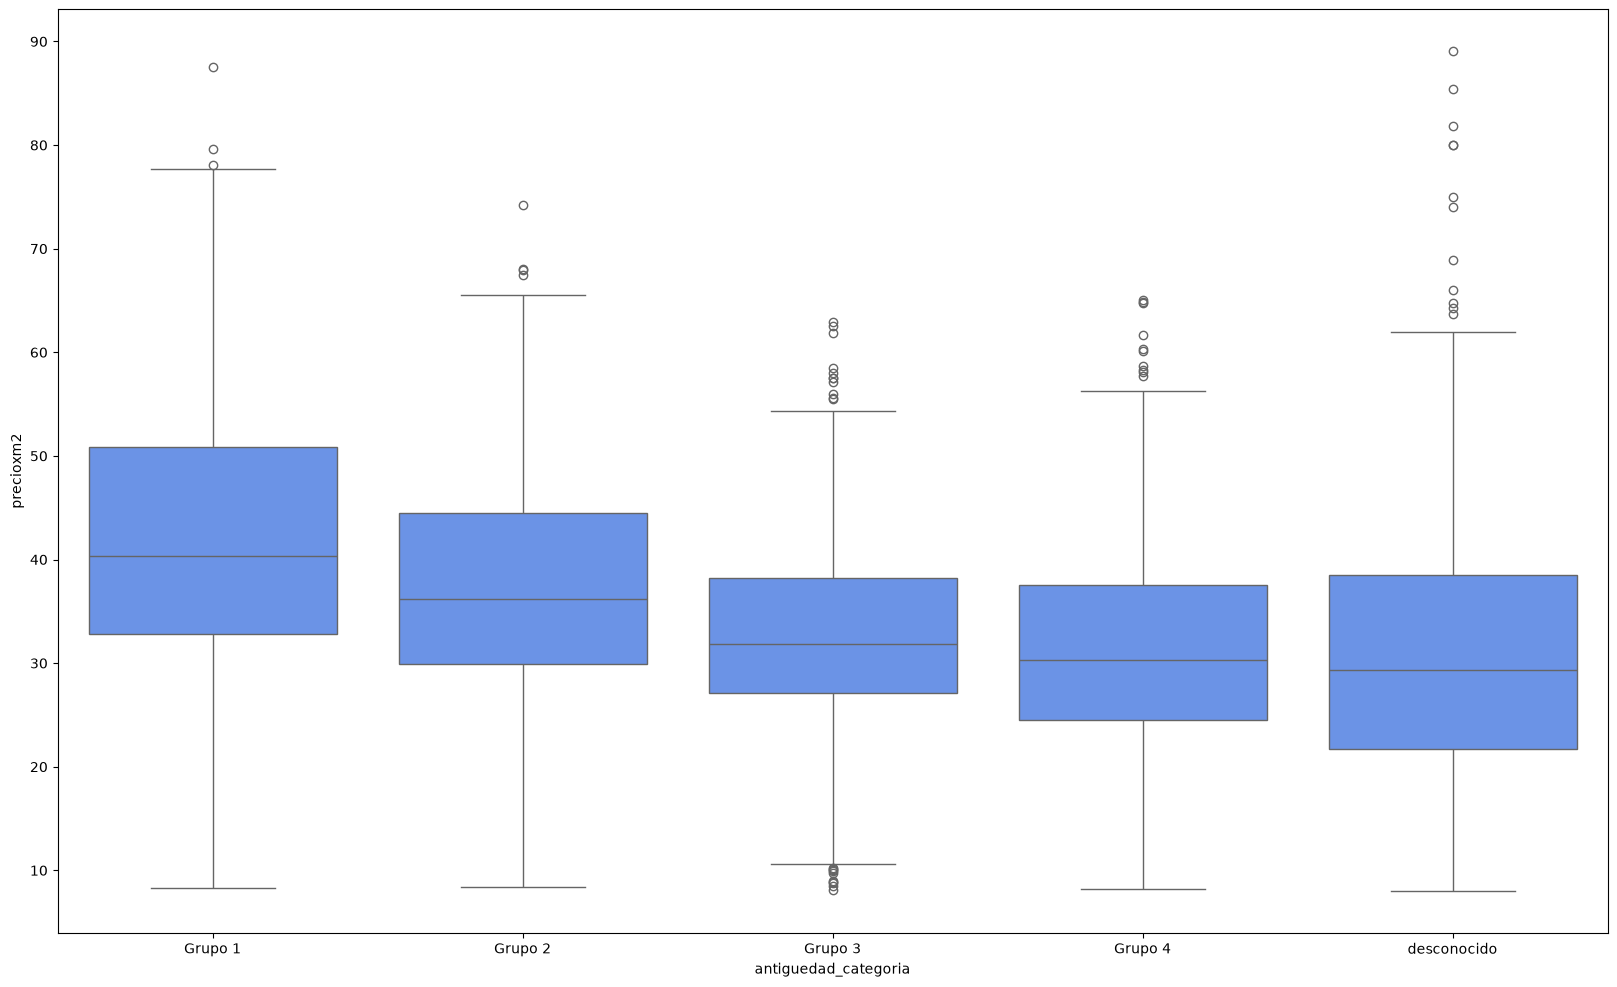

In [36]:
plt.figure(figsize=(20,12))
sns.boxplot(data=visualizacion_df,x='antiguedad_categoria',y='precioxm2',order=antiguedad_ordenada)
plt.show()


Observaciones:
- Se puede apreciar una **tendencia a la baja**, es decir, a medida que aumenta la antiguedad del departamento el precio de cada m2 tiende a ser menor o dicho de otro modo a departamentos más nuevos el precio de cada m2 es mayor.
- Se puede ver que antes cada m2 de un departamento costaba **S/32.5** en promedio y ahora cada m2 de un departamento cuesta **S/40**. 
- **Hipotesis: Los departamentos más recientes poseen un mayor precio por cada m2 que los antiguos.**

 **2.8. Precio vs Dormitorios, Precio vs baños**
 
Relación entre el número de dormitorios y el precio del departamento. 

- Como afecta el número de dormitorios o baños al precio de un departamento?
- A mayor cantidad de dormitorios y baños el precio de un departamento aumenta?
  
Para poder aislar y comprender el efecto real del número de dormitorios (o baños) sobre el precio, es fundamental controlar el área. Al analizar el precioxm2 se elimina la influencia directa del tamaño total del inmueble, permitiéndonos evaluar si, manteniendo constante el área, un mayor número de dormitorios (o baños) se asocia a diferencias en el precio. Esto nos ayuda a determinar si el mayor "aprovechamiento" del espacio, que puede implicar habitaciones más pequeñas o un diseño menos óptimo, se traduce en una reducción del precio por metro cuadrado, pese a que el precio total pueda ser mayor debido al mayor tamaño.


In [37]:
visualizacion_df.groupby(["distrito_clase","dormitorios"])['precioxm2'].describe()

count       mean        std        min        25%  \
distrito_clase dormitorios                                                      
clase1         1            447.0  47.802912  13.817355   8.235294  40.000000   
               2            420.0  39.340570  11.788196   8.035714  32.875125   
               3            358.0  35.818798  10.287297   8.152174  31.187500   
               4             32.0  34.544887   9.110046  10.215054  29.000000   
               5              2.0  31.669456   3.563049  29.150000  30.409728   
clase2         1            215.0  39.789425  11.792100  10.596026  31.250000   
               2            349.0  31.129607  11.057650   8.518987  25.000000   
               3            512.0  29.270384   9.512684   8.000000  25.000000   
               4             40.0  24.912295   8.743487   8.261364  19.908302   
               5              5.0  29.452771   6.474802  23.259184  26.600985   
clase3         1            207.0  36.652871  11.165932   9.333333  28.333333   
               2            290.0  28.296582   8.838047   8.333333  22.200000   
               3            370.0  25.820669   6.865597   8.064516  21.451175   
               4             25.0  24.485910  10.134973   9.214286  17.857143   
               5              4.0  19.889706   4.202770  16.250000  16.250000   

                                  50%        75%        max  
distrito_clase dormitorios                                   
clase1         1            47.619048  55.555556  89.074074  
               2            39.740179  45.681673  71.883333  
               3            35.968750  40.472984  75.200000  
               4            32.401705  41.718531  52.214815  
               5            31.669456  32.929184  34.188912  
clase2         1            40.909091  48.176393  69.550000  
               2            32.760417  38.333333  55.500000  
               3            30.225919  35.009124  64.870130  
               4            25.858586  30.912500  44.047619  
               5            26.600985  30.802703  40.000000  
clase3         1            36.517857  43.011905  66.034483  
               2            27.060924  33.087876  58.142857  
               3            26.315789  30.096154  51.388889  
               4            22.868932  29.125406  47.250000  
               5            19.889706  23.529412  23.529412

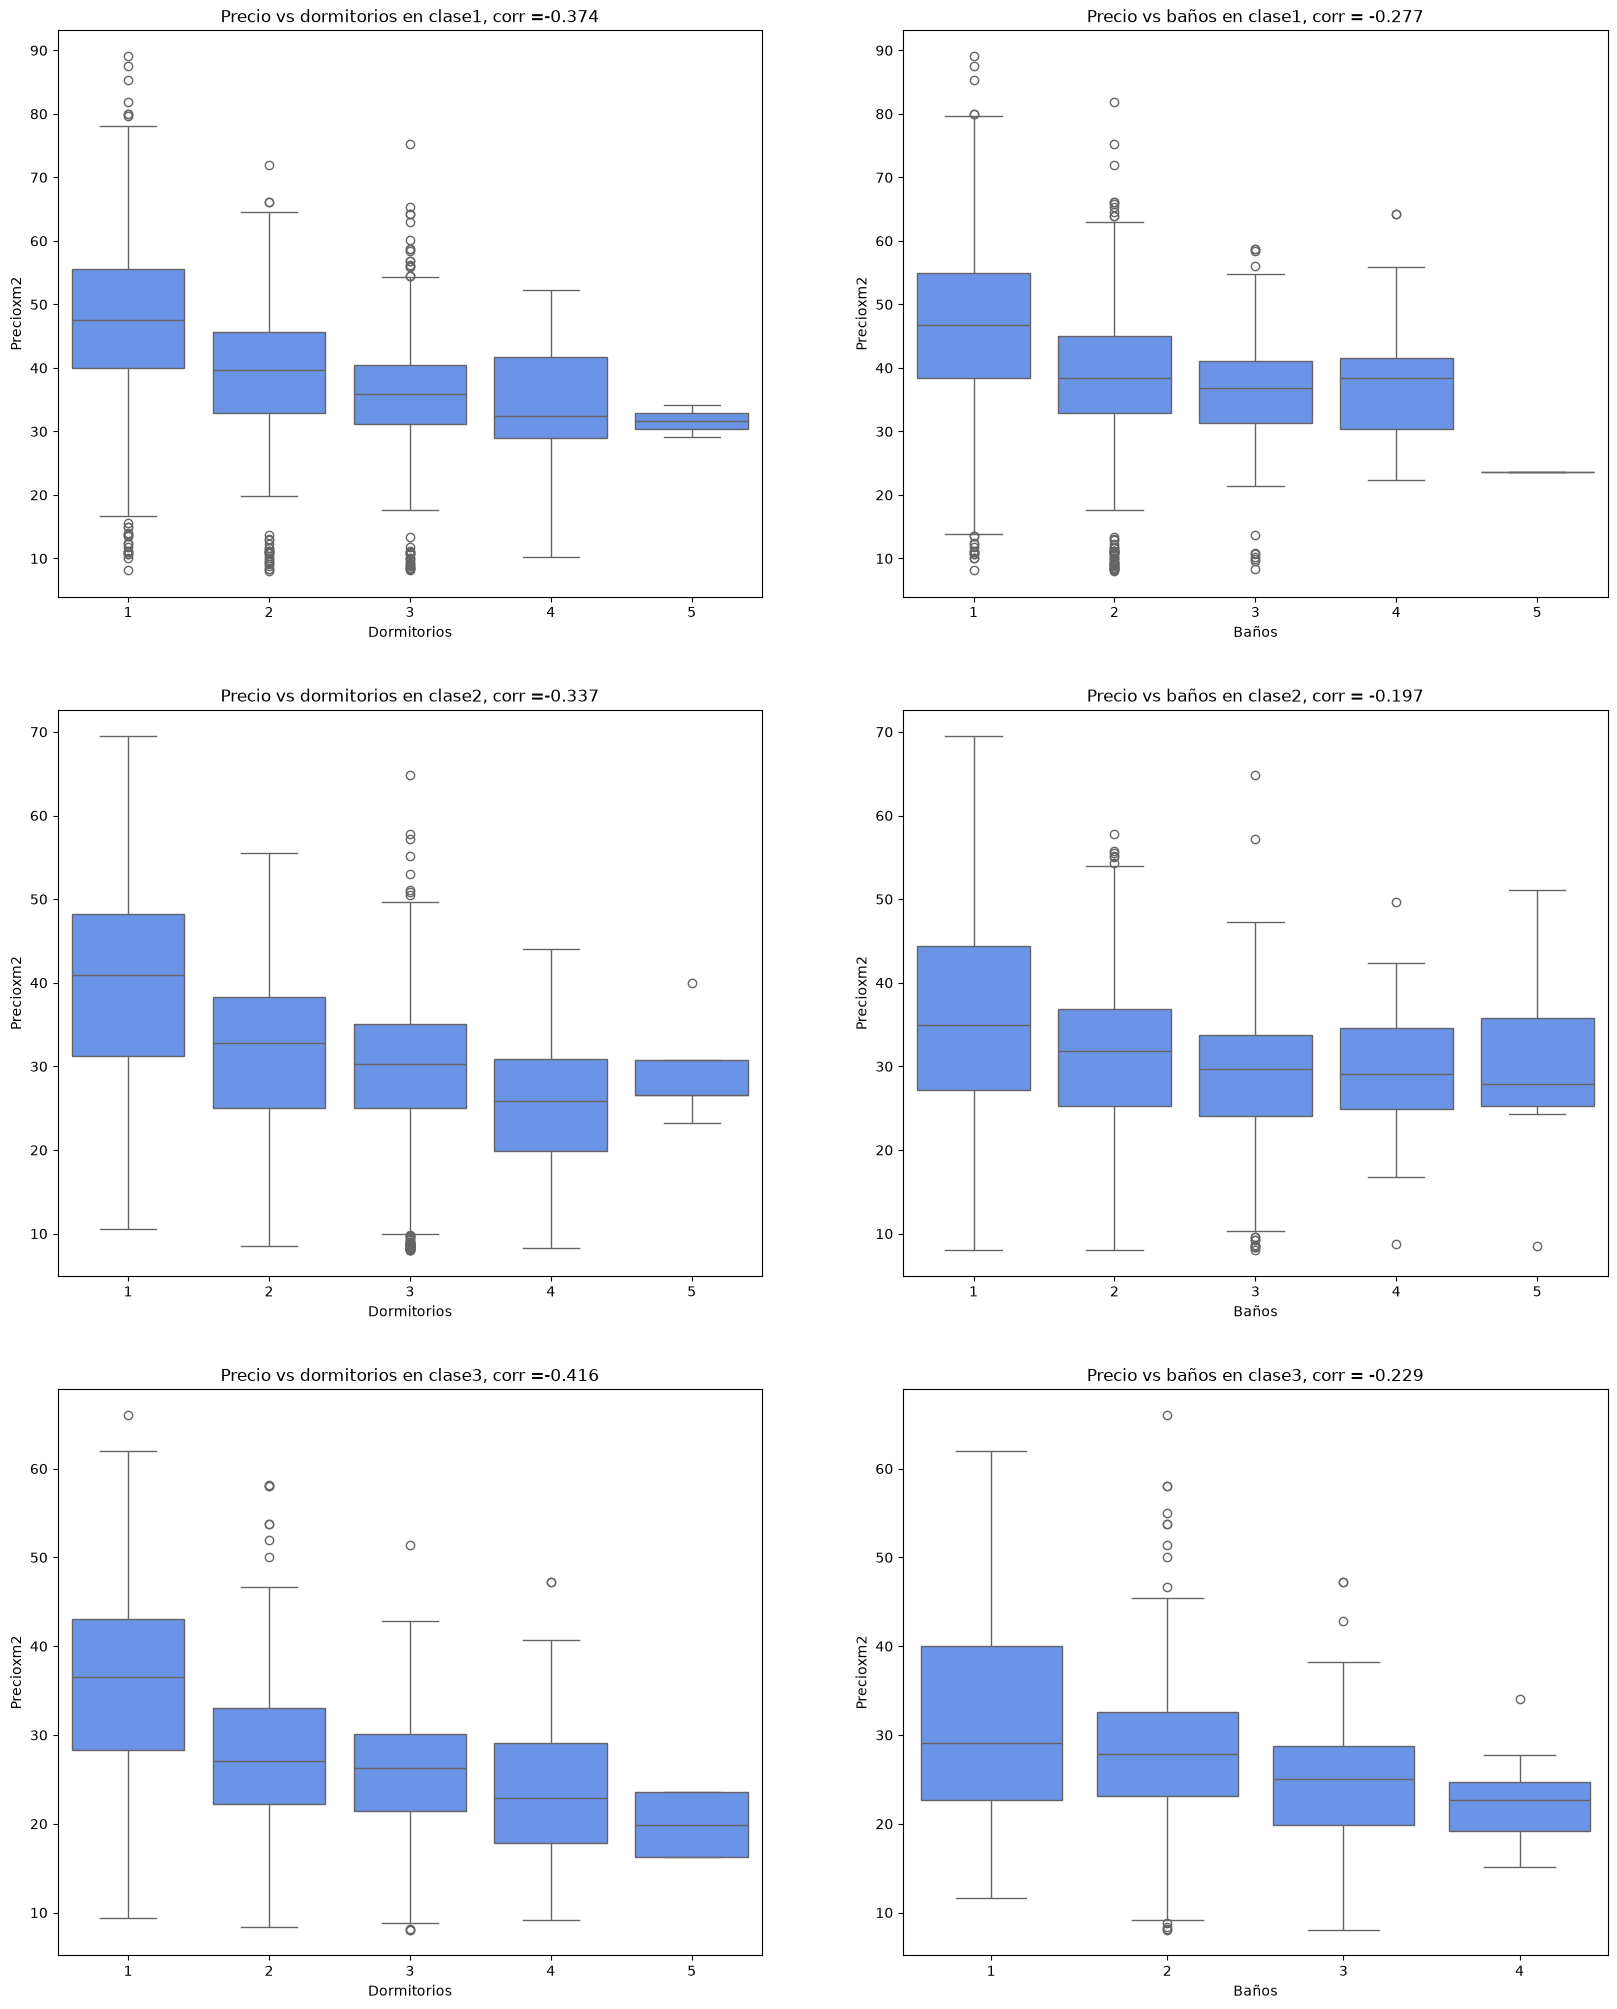

In [38]:
fig, ax = plt.subplots(3,2,figsize=(20,25))
for i,clase in enumerate(['clase1','clase2','clase3']):
    df_grupo = visualizacion_df[visualizacion_df['distrito_clase']==clase]
    
    corr = df_grupo[['precioxm2','dormitorios']].corr().values[0][1]
    sns.boxplot(data=df_grupo, x='dormitorios', y='precioxm2', ax=ax[i,0])
    ax[i,0].set_title(f'Precio vs dormitorios en {clase}, corr ={corr:.3f}')
    ax[i,0].set_xlabel('Dormitorios')
    ax[i,0].set_ylabel('Precioxm2')

    corr = df_grupo[['precioxm2','banos']].corr().values[0][1]
    sns.boxplot(data=df_grupo, x='banos', y='precioxm2', ax=ax[i,1])
    ax[i,1].set_title(f'Precio vs baños en {clase}, corr = {corr:.3f}')
    ax[i,1].set_xlabel('Baños')
    ax[i,1].set_ylabel('Precioxm2')

Observaciones:

- De la correlación analizada anteriormente habíamos visto que existe una correlación positiva entre el precio y el numero de dormitorios y el precio y el numero de baños, sin embargo, esto se puede deber a un efecto más que nada del área sobre el precio que de los dormitorios sobre el precio, ya que a mayor dormitorios mayor area y por ende mayor precio, sin embargo, cuando analizamos el precioxm2 (eliminando el factor area que influye directamente) podemos notar que existe una correlación negativa importante entre la cantidad de dormitorios  y baños sobre el precio, es decir, para 2 departamentos con igual area el departamento con más dormitorios (o con más baños) sera más económico, por ejemplo, para un departamento de **80m2**, en los distritos de **clase1**, el precioxm2 que sugiere la grafica es de aproximadamente **S/50** para **1 dormitorio**, esto implica que el precio del departamento sea de **S/4000**, ahora si buscamos un departamento con las mismas características y con 1 dormitorio más (**2 dormitorios**), la grafica sugiere que el precioxm2 promedio es de **S/40**, lo que implica que deberia costar **3200 soles** (más barato).
- Si bien es cierto acabamos de eliminar el factor area, que era determinante, aun existe el factor baños cuando analizamos dormitorios vs precio y el fator dormitorios cuando analizamos baños vs precio, por lo que para estar seguros del efecto que produce cada variable es necesario utilizar un modelo de regresión lineal múltiple que incluye a esas varaibles como predictores,para poder obtener el efecto "independiente" de cada uno sobre el precio.
- **Hipótesis: Para propiedades de igual área, un mayor número de dormitorios (o de baños) se asocia con un precio por metro cuadrado menor, lo que sugiere que, al controlar por el tamaño, la mayor compartimentación del espacio influye negativamente en el precio del inmueble.**

**2.9. antiguedad vs dormitorios+banos**

Relación entre el número de baños y el precio del departamento. 

- Como afecta la antiguedad al numero de dormitorios y baños de un departamento?
- Departamentos más antiguos poseen mayor número de dormitorios y baños?
 

In [39]:
visualizacion_df.groupby("antiguedad_categoria")['dorm+ban'].describe()

,count,mean,std,min,25%,50%,75%,max
antiguedad_categoria,,,,,,,,
Grupo 1,732.0,3.644809,1.395542,2.0,2.0,4.0,5.0,9.0
Grupo 2,549.0,3.956284,1.490206,2.0,2.0,4.0,5.0,9.0
Grupo 3,556.0,4.469424,1.517751,2.0,4.0,5.0,5.0,9.0
Grupo 4,577.0,4.266898,1.528035,2.0,3.0,4.0,5.0,9.0
desconocido,862.0,3.901392,1.492769,2.0,2.0,4.0,5.0,9.0


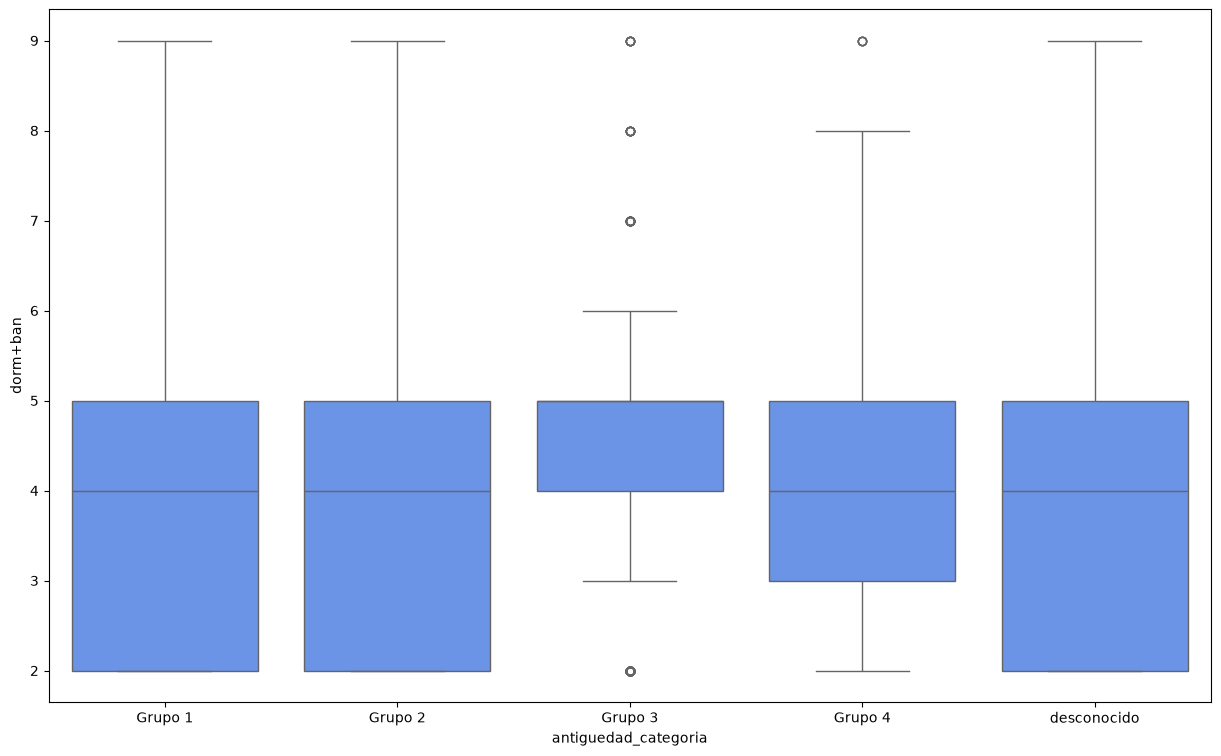

In [40]:
plt.figure(figsize=(15,9))
sns.boxplot(data=visualizacion_df,x='antiguedad_categoria',y='dorm+ban',order=antiguedad_ordenada)
plt.show()

Observaciones:

- Como se esperaba, a más baños el precio suele ser mayor, esto también se debe a que existe una mayor área cuando existe un número mayor de baños.
- Se puede ver ademas que existe un gran porcentaje de outliers superiores en el precio para departamentos con 2 baños.
- **Hipotesis: La distribucion de dormitorios y baños sigue siendo la misma en departamentos más recientes**

**2.10. antiguedad-distrito**

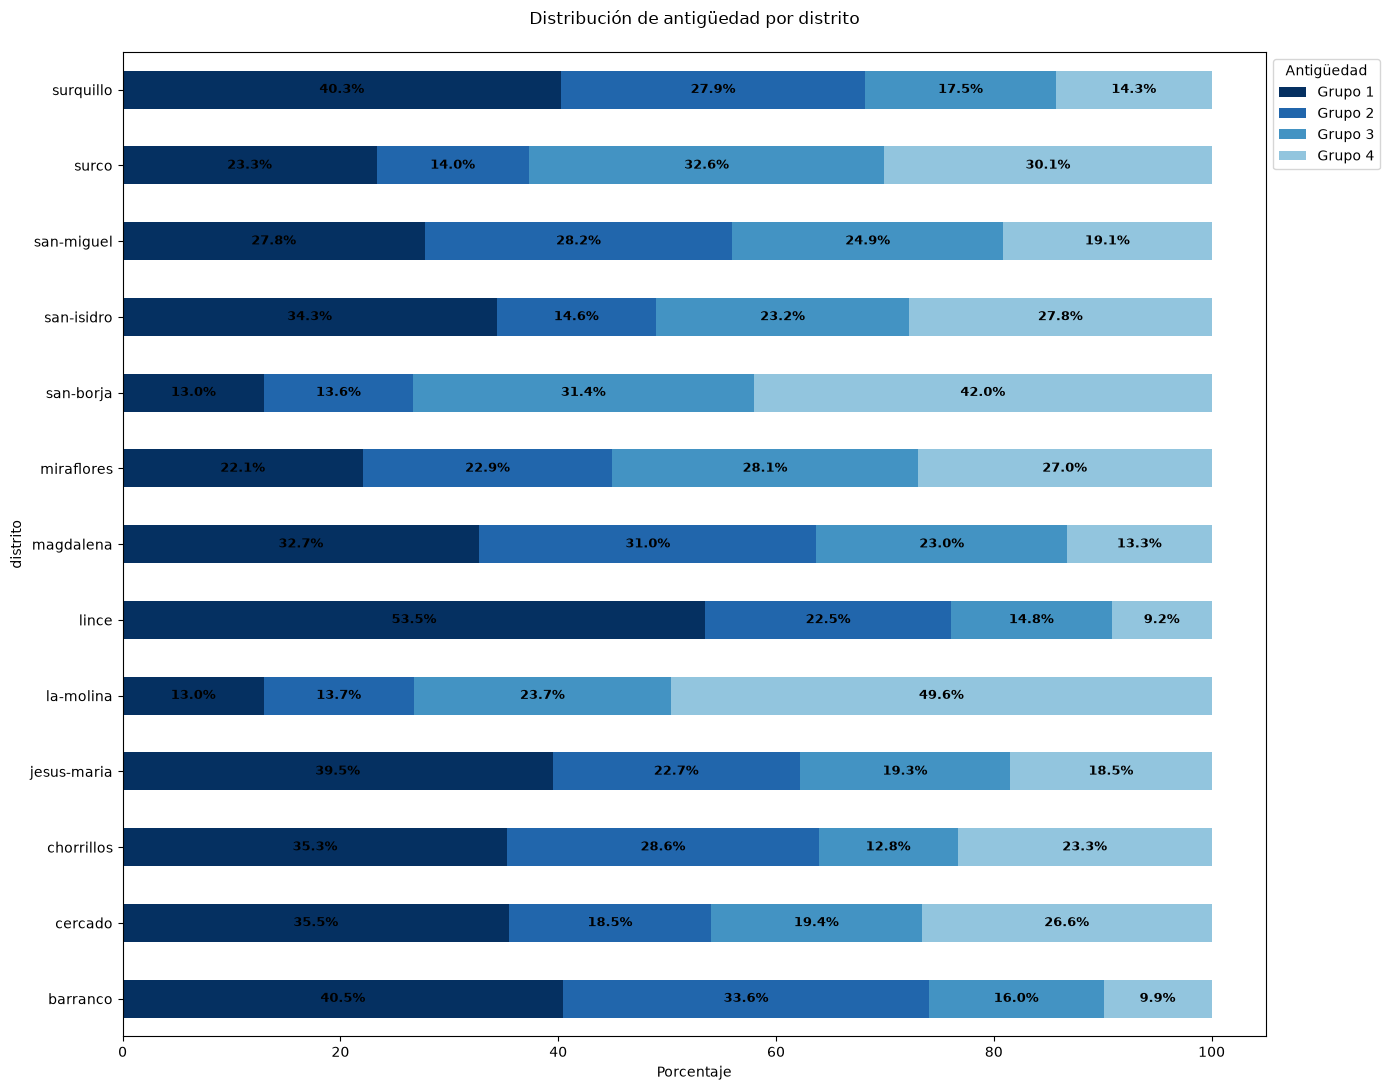

In [41]:

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

df_copia = visualizacion_df.copy()
df_copia['antiguedad_categoria'] = np.where(data['antiguedad_categoria']=='desconocido',np.nan,data['antiguedad_categoria'])

# Crear tabla de frecuencias
tabla_contingencia = pd.crosstab(df_copia['distrito'], df_copia['antiguedad_categoria'])

# Convertir a proporciones (%)
tabla_porcentajes = tabla_contingencia.div(tabla_contingencia.sum(axis=1), axis=0) * 100

# Definir colores neutros
colores_azules = ['#053061', '#2166ac', '#4393c3', '#92c5de', '#d1e5f0']

# Graficar horizontalmente
fig, ax = plt.subplots(figsize=(14,11))  # Ajustamos el tamaño para adaptarse a barras horizontales
tabla_porcentajes.plot(kind='barh', stacked=True, ax=ax, color=colores_azules)

# Añadir porcentajes dentro de las barras (ajustado para orientación horizontal)
for i, barras in enumerate(ax.containers):
    for bar in barras:
        ancho = bar.get_width()
        if ancho > 5:  # Evitar etiquetas en porcentajes muy pequeños
            ax.text(bar.get_x() + ancho/2, bar.get_y() + bar.get_height()/2, f'{ancho:.1f}%',
                    ha='center', va='center', fontsize=9, color='black', fontweight='bold')

# Personalizar el gráfico
ax.set_xlabel('Porcentaje')  # Ahora el eje X representa el porcentaje
ax.set_title('Distribución de antigüedad por distrito', pad=20)
ax.legend(title='Antigüedad', bbox_to_anchor=(1, 1))

# Ajustar los márgenes para que quepa todo
plt.tight_layout()
plt.show()


**2.11. fecha_publicacion vs precio**

Relacion entre la fecha de publicacion y el precio

- Existen diferencias significativas entre el precio de departamentos en alquiler publicados este mes con los departamentos publicados meses anteriores? 


In [42]:
visualizacion_df.groupby("fecha_publicacion")['precio'].describe().T

fecha_publicacion,0,1
count,3005.000000,271.000000
mean,2968.083062,3670.357934
std,1965.807525,2803.180606
min,600.000000,950.000000
25%,1900.000000,2200.000000
50%,2500.000000,2672.000000
75%,3350.000000,3750.000000
max,18000.000000,19855.000000


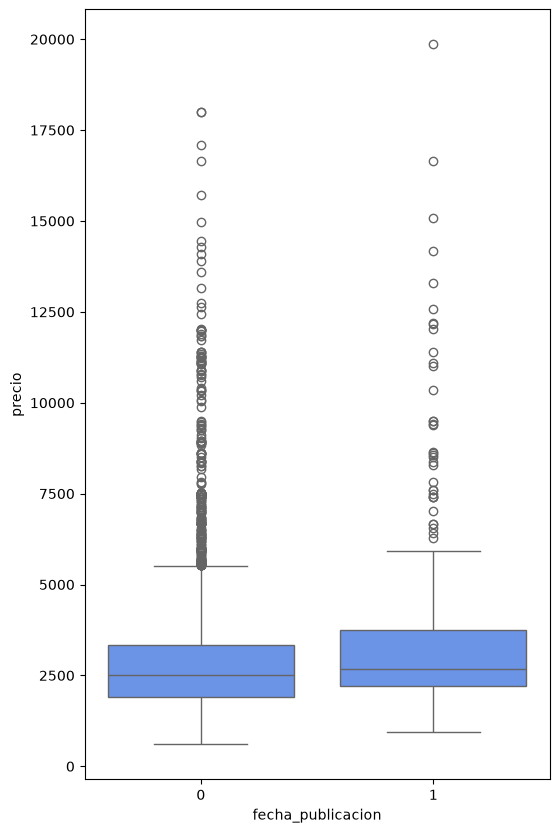

In [43]:
plt.figure(figsize=(6,10))
sns.boxplot(data=visualizacion_df,x='fecha_publicacion',y='precio')
plt.show()


Observaciones:

- Aparentemnente no existe una diferencia significativa tan grande con departamentos publicados este mes y los publicados meses anteriores, se puede ver que existe una diferencia promedio del 7%.
- **Hipostesis: Los departamentos publicados este mes no poseen precios diferentes a los precios del mes pasado**

**2.12. coordenadas vs distritos vs precioxm2**

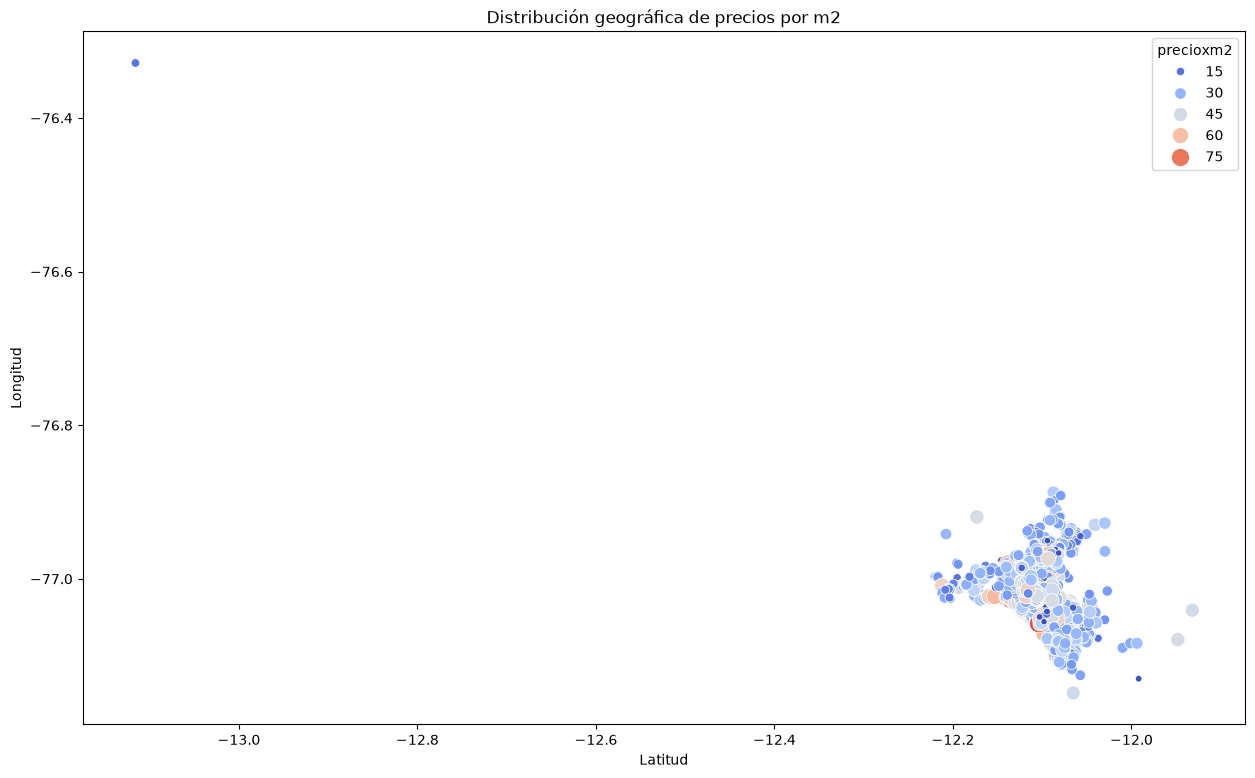

In [44]:
plt.figure(figsize=(15,9))
sns.scatterplot(data=visualizacion_df, x='latitud', y='longitud', size='precioxm2', sizes=(20, 200), hue='precioxm2', palette='coolwarm')
plt.title('Distribución geográfica de precios por m2')
plt.xlabel('Latitud')
plt.ylabel('Longitud')
plt.show()

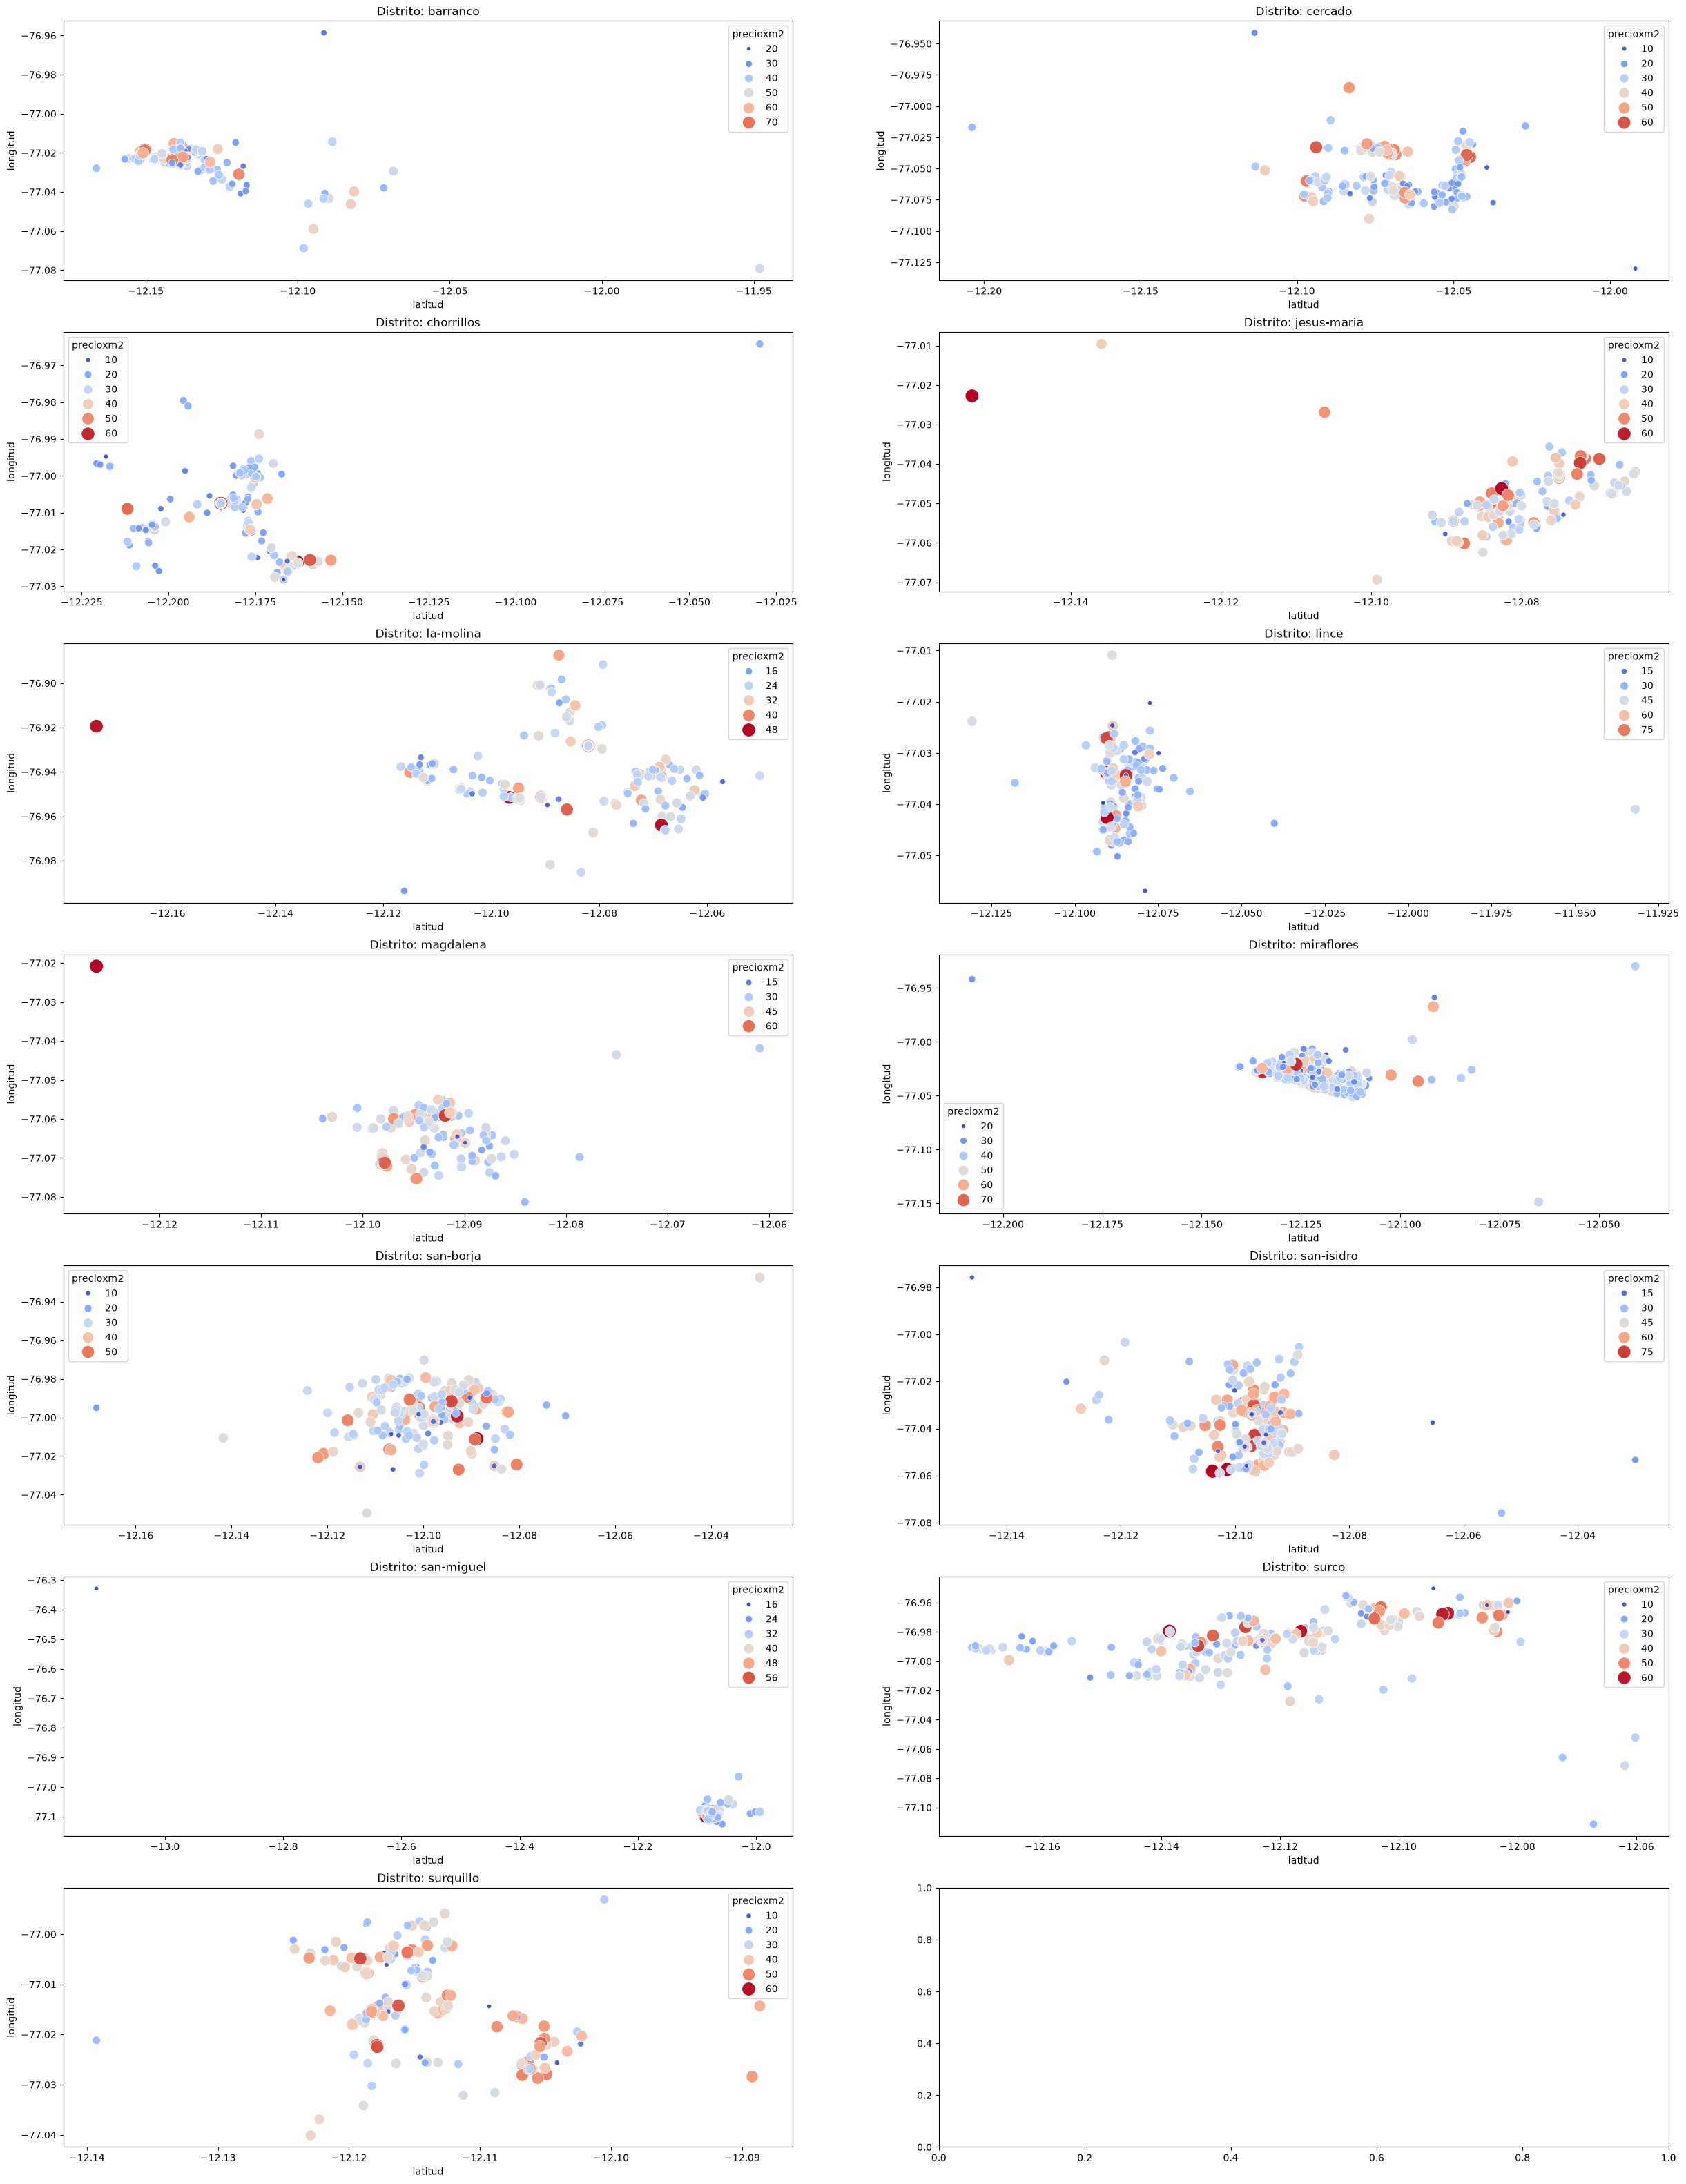

In [45]:
fig, ax = plt.subplots(7,2,figsize=(30,40))
for i,distrito in enumerate(visualizacion_df['distrito'].unique()):
    f,c = i//2,i%2
    sns.scatterplot(data=visualizacion_df.query(f"distrito=='{distrito}'"),
                    x='latitud',
                    y='longitud',
                    size='precioxm2',
                    sizes=(20, 200),
                    hue='precioxm2',
                    palette='coolwarm',
                    ax=ax[f,c]
                    )
    ax[f,c].set_title(f'Distrito: {distrito}')
fig.show()
                    

**2.13. distrito-dormitorios**

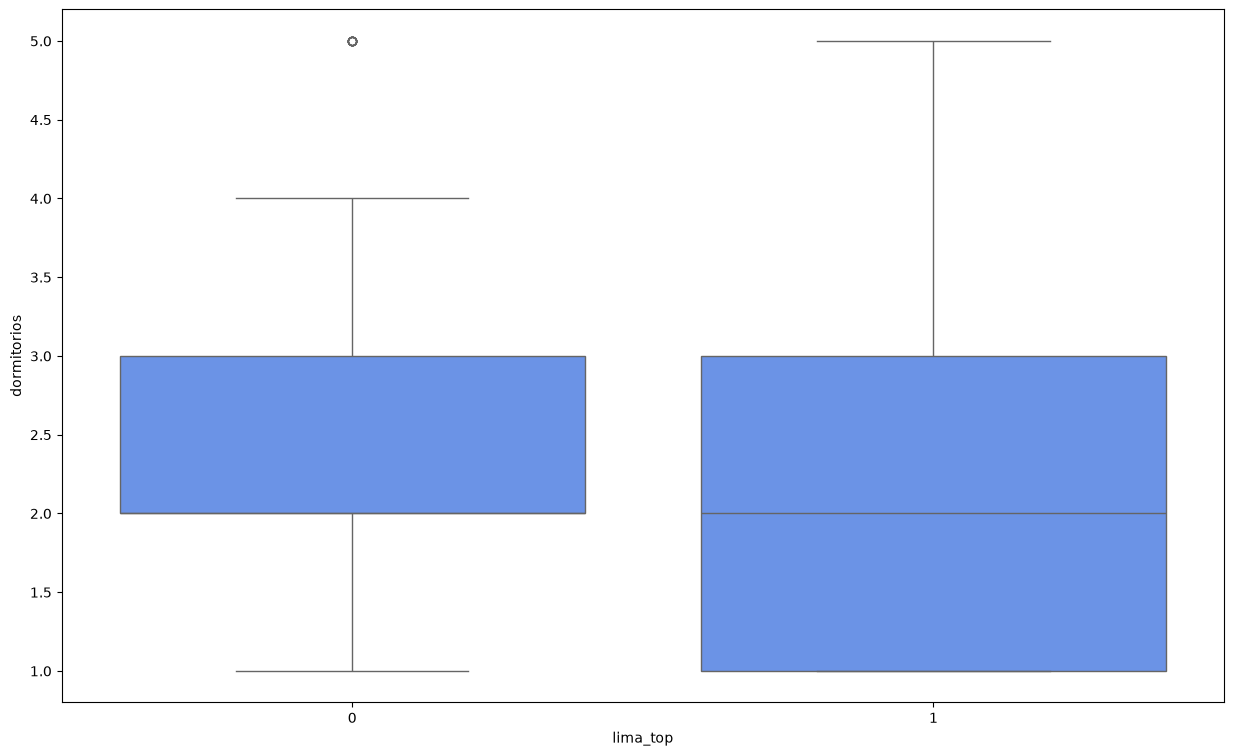

In [46]:
plt.figure(figsize=(15,9))
sns.boxplot(data=visualizacion_df,x='lima_top',y='dormitorios')
plt.show()

## 4. Planteamiento de hipotesis

In [47]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from scipy.stats import kruskal
import scipy.stats as stats
from scipy.stats import spearmanr

In [48]:
hipotesis_df = data.copy()
hipotesis_df['lima_top'] = np.where(data['distrito'].isin(['barranco','san-isidro','miraflores','lince']),1,0)
hipotesis_df['precioxm2'] = data['precio']/data['area']
hipotesis_df['precioxm2_log'] = np.log(hipotesis_df['precioxm2'])
hipotesis_df['precio_log'] = np.log(hipotesis_df['precio'])
hipotesis_df['area_log'] = np.log(hipotesis_df['area'])
hipotesis_df['distrito_clase'] =  hipotesis_df['distrito'].map({
    "miraflores":"clase1",
    "san-isidro":"clase1",
    "barranco":"clase1",
    "lince":"clase1",
    "magdalena":"clase2",
    "surquillo":"clase2",
    "jesus-maria":"clase2",
    "san-borja":"clase2",
    "surco":"clase2",
    "cercado":"clase3",
    "san-miguel":"clase3",
    "chorrillos":"clase3",
    "la-molina":"clase3"
})



### Aseveracion 1: Existe una diferencia significativa entre el precio promedio de cada m2 en los distritos considerados de Lima-Top

Determinar si existen diferencias significativas en el precio por m2 entre los distritos clasificados como "Lima-Top" (Barranco, Miraflores, San Isidro) y Lince (potencial nuevo distrito top).

- Ho: μ_barranco = μ_miraflores = μ_san_isidro = μ_Lince
- Ha: Al menos un par de distritos tiene precios por m² significativamente diferentes.


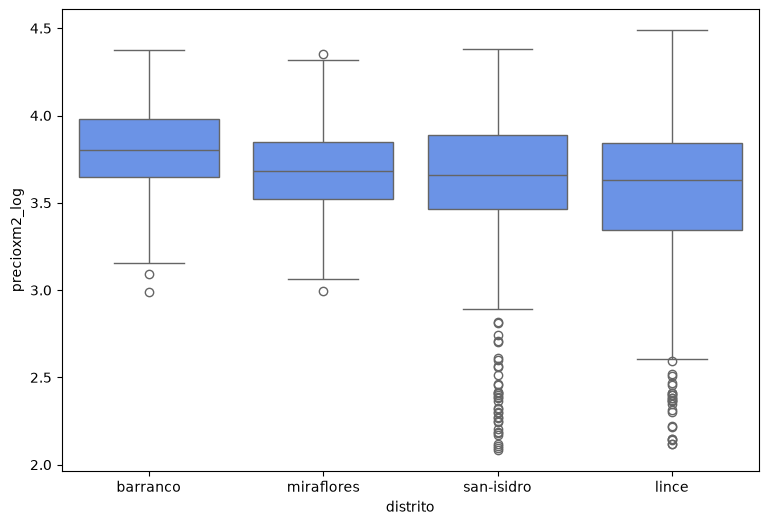

In [49]:
index = hipotesis_df.query("lima_top==1").groupby('distrito')['precioxm2_log'].mean().sort_values(ascending=False).index
plt.figure(figsize=(9,6))
sns.boxplot(data=hipotesis_df.query("lima_top==1"),x='distrito',y='precioxm2_log',order=index)
plt.show()

Podemos ver en el gráfico que Barranco tiene una mediana y una distribución notablemente más alta que la de los otros distritos.

Ademas podemos ver que el distrito de Lince tiene una mediana superior al de san isidro y miraflores, sin embargo, tiene outliers inferiores que podrían reducir su promedio y hacer que sea significativamente diferente a los distritos de San Isidro y Miraflores.

In [50]:
data_tukey = hipotesis_df[hipotesis_df['distrito'].isin(['miraflores', 'san-isidro', 'barranco','lince'])]

tukey_result = pairwise_tukeyhsd(endog=data_tukey['precioxm2_log'],
                                 groups=data_tukey['distrito'],
                                 alpha=0.05)

print(tukey_result)

    Multiple Comparison of Means - Tukey HSD, FWER=0.05     
  group1     group2   meandiff p-adj   lower   upper  reject
------------------------------------------------------------
  barranco      lince  -0.2634    0.0   -0.35 -0.1769   True
  barranco miraflores  -0.0927 0.0086  -0.168 -0.0174   True
  barranco san-isidro  -0.2135    0.0 -0.2971 -0.1298   True
     lince miraflores   0.1708    0.0   0.094  0.2475   True
     lince san-isidro     0.05 0.4297  -0.035   0.135  False
miraflores san-isidro  -0.1208 0.0001 -0.1943 -0.0473   True
------------------------------------------------------------


Observaciones (valores de la salida anterior):
- **Barranco** tiene un precio por m² significativamente mayor que los otros tres distritos (todas las comparaciones con p ajustado < 0.01).
- **Miraflores** también difiere significativamente de **Lince** (diferencia de 0.171 en log, p < 0.001) y de **San Isidro** (0.121, p = 0.0001): su precio por m² es mayor que el de ambos.
- **Lince y San Isidro** no presentan una diferencia significativa (p = 0.43).

Conclusiones:

1. El distrito con mayor precio por m² es Barranco, con una diferencia notable.
2. Le sigue Miraflores; San Isidro y Lince forman un tercer grupo sin diferencias entre sí.
3. Como las distribuciones tienen colas (outliers inferiores en Lince), se complementa con una prueba de Kruskal-Wallis que compara medianas.

### Aseveracion2: No existe una diferencia significativa entre la mediana del precio del m2 entre San Isidro, Lince y Miraflores.

Determinar si existen diferencias significativas en el precio del m2 en los distritos de Miraflores, San Isidro y Lince, todos clasificados como "Lima-Top".

- **$H_0$**: $\tilde{X}_{\text{Miraflores}} = \tilde{X}_{\text{San Isidro}} = \tilde{X}_{\text{Lince}}$
- **$H_a$**: Al menos un par de distritos tiene precios por m² con medianas significativamente diferentes.


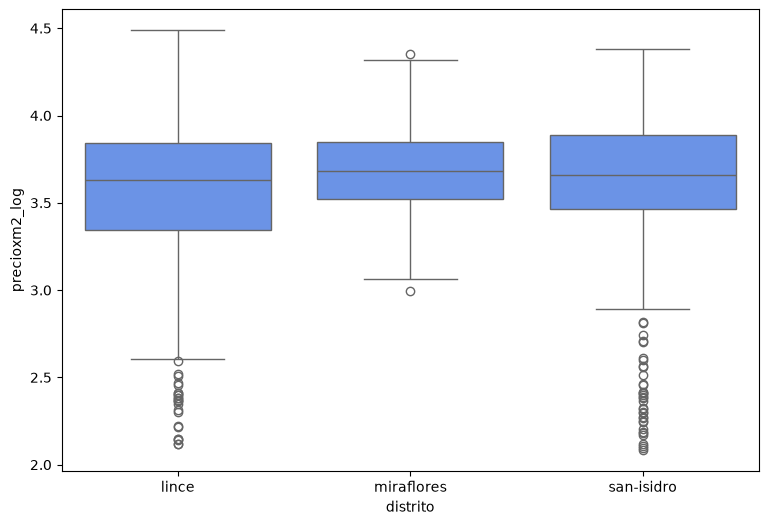

In [51]:
plt.figure(figsize=(9,6))
sns.boxplot(data=hipotesis_df.query("distrito.isin(['miraflores','lince','san-isidro'])"),
            x='distrito',y='precioxm2_log')
plt.show()

Como podemos ver en el gráfico, las medianas y distribuciones de los distritos son muy similares.

In [52]:
miraflores = hipotesis_df[hipotesis_df['distrito']=='miraflores']['precioxm2_log']
san_isidro = hipotesis_df[hipotesis_df['distrito']=='san-isidro']['precioxm2_log']
lince = hipotesis_df[hipotesis_df['distrito']=='lince']['precioxm2_log']

kruskal_result = kruskal(miraflores, san_isidro, lince)
print(f"Kruskal-Wallis H-statistic: {kruskal_result.statistic:.3f}")
print(f"Kruskal-Wallis p-value: {kruskal_result.pvalue:.3f}")

Kruskal-Wallis H-statistic: 10.280
Kruskal-Wallis p-value: 0.006


Observaciones:
- El estadístico de Kruskal-Wallis es H = 10.28 con **p = 0.006 < 0.05**, por lo que **se rechaza la hipótesis nula**: al menos uno de los tres distritos tiene una mediana de precio por m² distinta.
- Combinado con Tukey, la diferencia proviene de Miraflores (más caro); San Isidro y Lince no difieren entre sí.

Conclusiones:
1. Las medianas del precio por m² de Miraflores, San Isidro y Lince **no** son iguales: Miraflores está por encima.
2. San Isidro y Lince sí pueden considerarse similares (Tukey, p = 0.43).

### Aseveracion3 : El precio de cada m2 en los distritos de lima-top es en promedio un 30% más caro que en los distritos no lima-top.

El objetivo es poder determinar, como vimos en el EDA, si el precio de cada m2 en los distritos de lima-top son en promedio un 30% mas caros que en los distritos que no pertenecen al lima_top.

- Ho: $\mu_{\text{adjusted\_log\_top}} - \mu_{\text{log\_no\_top}} = 0$
- H1: $\mu_{\text{adjusted\_log\_top}} - \mu_{\text{log\_no\_top}} > 0$

Usaremos el logaritmo del precioxm2 para controlar los outliers superiores que afectan la media y varianza, ademas nos ayuda a que la distribución sea mas cercana a la normal

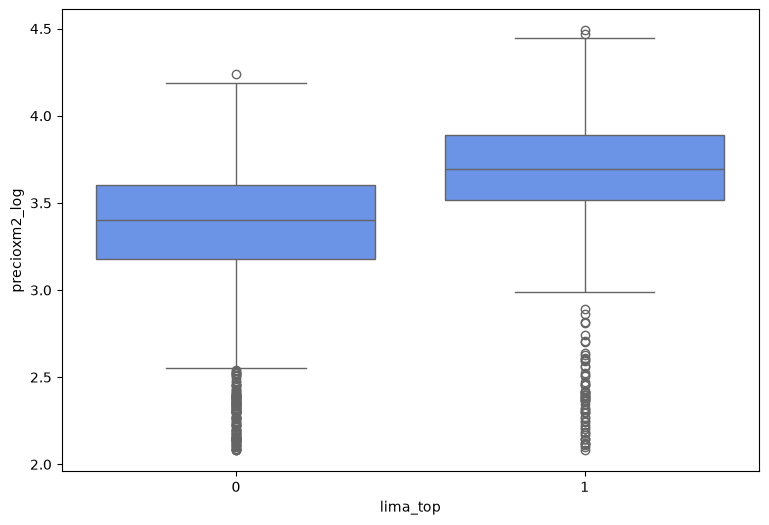

In [53]:
plt.figure(figsize=(9,6))
sns.boxplot(data=hipotesis_df,x='lima_top',y='precioxm2_log')
plt.show()

Como podemos ver en la grafica si existe una diferencia significativa notable entre los distritos de lima-top y no lima-top.

In [54]:

# Dividir los datos en grupos
log_top = hipotesis_df[hipotesis_df['lima_top'] == 1]['precioxm2_log']
log_no_top = hipotesis_df[hipotesis_df['lima_top'] == 0]['precioxm2_log']

# Transformar el grupo de lima_top restándole log(1.30)
adjusted_log_top = log_top - np.log(1.30)

# homocedasticidad
_, p_levene = stats.levene(log_top, log_no_top)
equal_var = p_levene > 0.05

stat, p_value = stats.ttest_ind(
    adjusted_log_top, log_no_top, equal_var=equal_var, alternative='greater'
)

diferencia = np.exp(log_top.mean()-log_no_top.mean())

print(f"Diferencia observada: {diferencia:.3f}")
print(f"Estadistico: {stat:.3f}")
print(f"t-test (alternativa 'greater'): p = {p_value:.5f}")

Diferencia observada: 1.360
Estadistico: 3.182
t-test (alternativa 'greater'): p = 0.00074


Observaciones:

- La razón entre los precios por m² de lima_top y no_top es **1.360**: en promedio, los precios en lima_top son aproximadamente **36 % más altos**.
- El p-valor (unilateral) de **0.00074** es menor que 0.05, por lo que hay evidencia para concluir que la diferencia es **de al menos 30 %**.

Conclusiones:
1. Los departamentos de lima_top son, en promedio, significativamente más caros por m² que los de no_top, con una diferencia de al menos 30 % (estimada en 36 %).
2. Esta comparación no controla tamaño, antigüedad ni otras características: es una diferencia descriptiva, no un efecto causal de la ubicación.

### Aseveracion 4: Los departamentos mas antiguos tienen un precio promedio mayor a la de los mas recientes

El objetivo es evaluar si existe una correlación positiva entre la antigüedad de los departamentos y su precio, es decir, si los departamentos más antiguos tienden a ser mas caros.

- Ho: No existe una correlación significativa entre la antigüedad de los departamentos y su precio ($\rho = 0$).
- H1: Existe una correlación positiva significativa entre la antigüedad de los departamentos y su precio ($\rho > 0$).

Usaremos la prueba de hipótesis de spearman que es ideal para ver si existe una relación monótona, no necesariamente lineal.

In [55]:
# Asignar valores numéricos a los grupos (1 a 4)
hipotesis_df_copia = hipotesis_df.copy()
hipotesis_df_copia['antiguedad_ordinal'] = hipotesis_df_copia['antiguedad_categoria'].map({
    'Grupo 1': 1, 'Grupo 2': 2, 'Grupo 3': 3, 'Grupo 4': 4
})

# Eliminar filas con datos faltantes
hipotesis_df_copia.dropna(inplace=True)

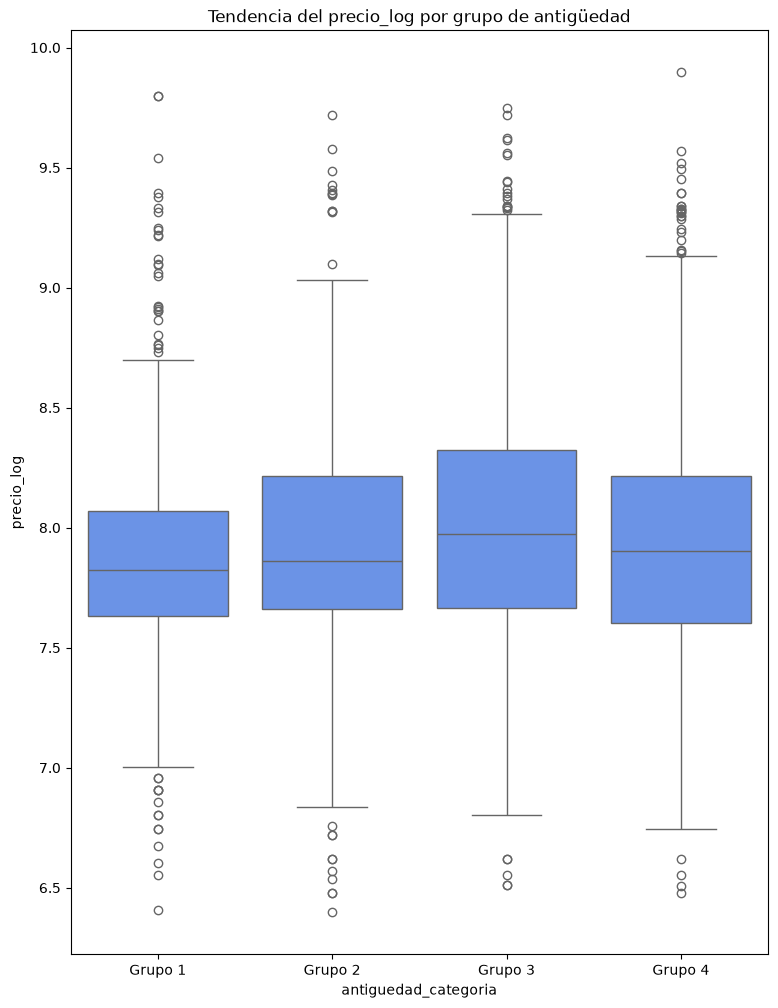

In [56]:
plt.figure(figsize=(9,12))
sns.boxplot(data=hipotesis_df, x='antiguedad_categoria', y='precio_log',order=[f'Grupo {i}' for i in range(1,5)])
plt.title("Tendencia del precio_log por grupo de antigüedad")
plt.show()

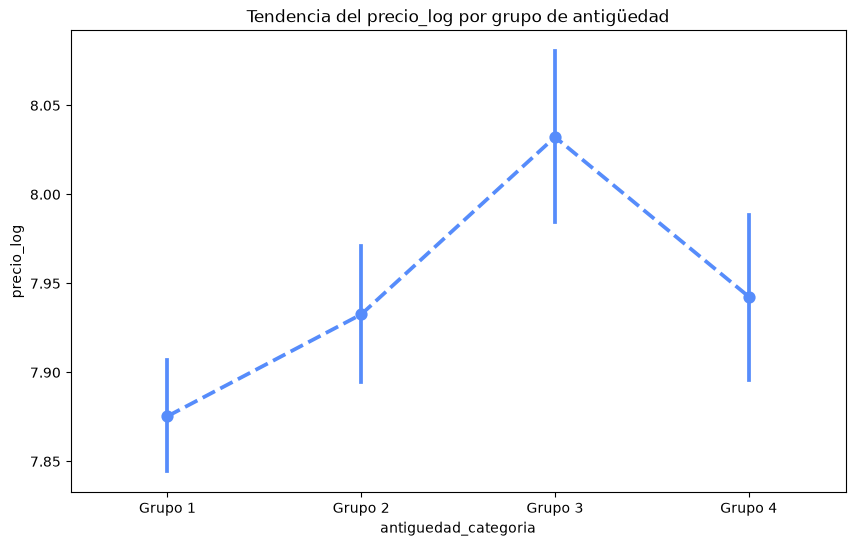

In [57]:
plt.figure(figsize=(10,6))
sns.pointplot(data=hipotesis_df,x='antiguedad_categoria',y='precio_log',order=[f'Grupo {i}' for i in range(1,5)],linestyle='--',)
plt.title("Tendencia del precio_log por grupo de antigüedad")
plt.show()

In [58]:
# Calcular correlación de Spearman (test bilateral por defecto)
rho, p_bilateral = spearmanr(hipotesis_df_copia['antiguedad_ordinal'], hipotesis_df_copia['precio_log'])

# Convertir a test unilateral (H₁: correlación positiva)
p_unilateral = p_bilateral / 2 if rho > 0 else 1 - p_bilateral / 2

print(f"Spearman's rho: {rho:.3f}")
print(f"p-valor (unilateral): {p_unilateral:.5f}")

Spearman's rho: 0.068
p-valor (unilateral): 0.00040


Observaciones:

- El coeficiente de Spearman (**ρ = 0.068**) indica una correlación positiva **muy débil** entre la antigüedad y el precio.
- El p-valor unilateral (**0.0004**) es menor que 0.05: la correlación es estadísticamente distinta de cero, aunque su magnitud es pequeña.

Conclusiones:

1. Los departamentos más antiguos tienden a tener un precio ligeramente mayor, pero la relación es muy débil.
2. Esta tendencia puede deberse a que los departamentos antiguos tienen más área, dormitorios y baños (ver aseveraciones 5 y 7).

### Aseveración 5: Los departamentos mas antiguos tienen un area promedio mayor a la de los mas recientes

El objetivo es evaluar si existe una correlación positiva entre la antigüedad de los departamentos y su área promedio, es decir, si los departamentos más antiguos tienden a tener una mayor superficie.

- Ho: No existe una correlación significativa entre la antigüedad de los departamentos y su área ($\rho = 0$).
- H1: Existe una correlación positiva significativa entre la antigüedad de los departamentos y su área ($\rho > 0$).

Usaremos la prueba de hipótesis de spearman que es ideal para ver si existe una relación monótona, no necesariamente lineal.

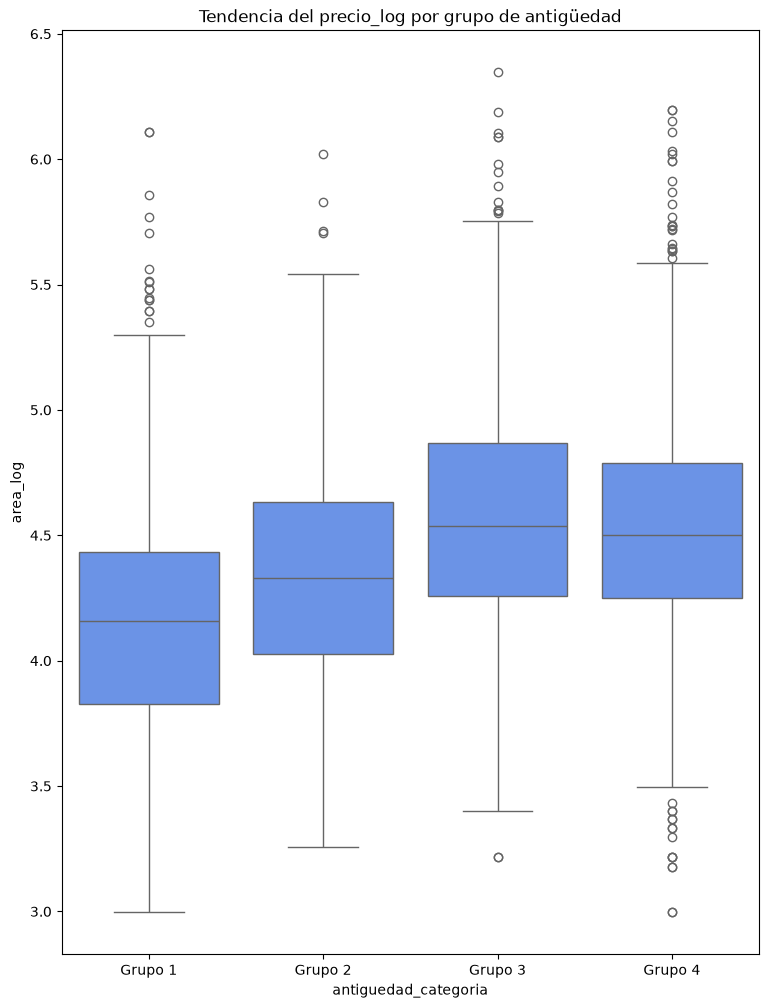

In [59]:
plt.figure(figsize=(9,12))
sns.boxplot(data=hipotesis_df, x='antiguedad_categoria', y='area_log',order=[f'Grupo {i}' for i in range(1,5)])
plt.title("Tendencia del precio_log por grupo de antigüedad")
plt.show()

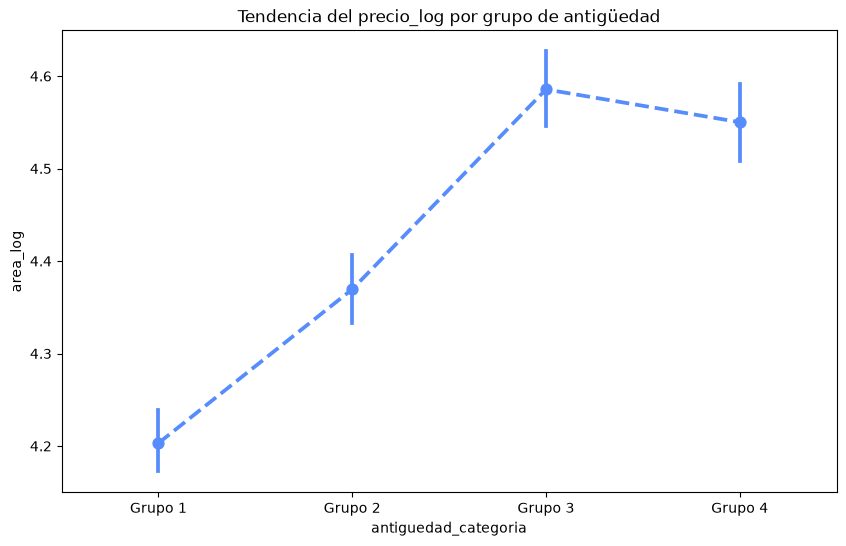

In [60]:
plt.figure(figsize=(10,6))
sns.pointplot(data=hipotesis_df,x='antiguedad_categoria',y='area_log',order=[f'Grupo {i}' for i in range(1,5)],linestyle='--',)
plt.title("Tendencia del precio_log por grupo de antigüedad")
plt.show()

In [61]:
# Calcular correlación de Spearman (test bilateral por defecto)
rho, p_bilateral = spearmanr(hipotesis_df_copia['antiguedad_ordinal'], hipotesis_df_copia['area_log'])

# Convertir a test unilateral (H₁: correlación positiva)
p_unilateral = p_bilateral / 2 if rho > 0 else 1 - p_bilateral / 2

print(f"Spearman's rho: {rho:.3f}")
print(f"p-valor (unilateral): {p_unilateral:.5f}")

Spearman's rho: 0.313
p-valor (unilateral): 0.00000


Observaciones:

- El coeficiente de Spearman (**ρ = 0.313**) indica una correlación positiva moderada entre la antigüedad y el área.
- El p-valor es prácticamente cero: la correlación es estadísticamente significativa.

Conclusiones:

1. Los departamentos más antiguos tienden a tener mayor superficie.
2. Esto es consistente con un mercado donde los departamentos recientes se construyen más pequeños para mantenerse asequibles.

### Aseveración 6: Los departamentos más antiguos tienen un precio por metro cuadrado mayor al de los más recientes

El objetivo es determinar si existe una correlación negativa entre la antigüedad de los departamentos y su precio por metro cuadrado, es decir, si los departamentos más antiguos tienden a tener un menor precio por m².

- Ho: No existe una correlación significativa entre la antigüedad de los departamentos y su precio por metro cuadrado ($\rho = 0$).
- H1: Existe una correlación negativa significativa entre la antigüedad de los departamentos y su precio por metro cuadrado ($\rho < 0$).

Usaremos la prueba de hipótesis de spearman que es ideal para ver si existe una relación monótona, no necesariamente lineal.

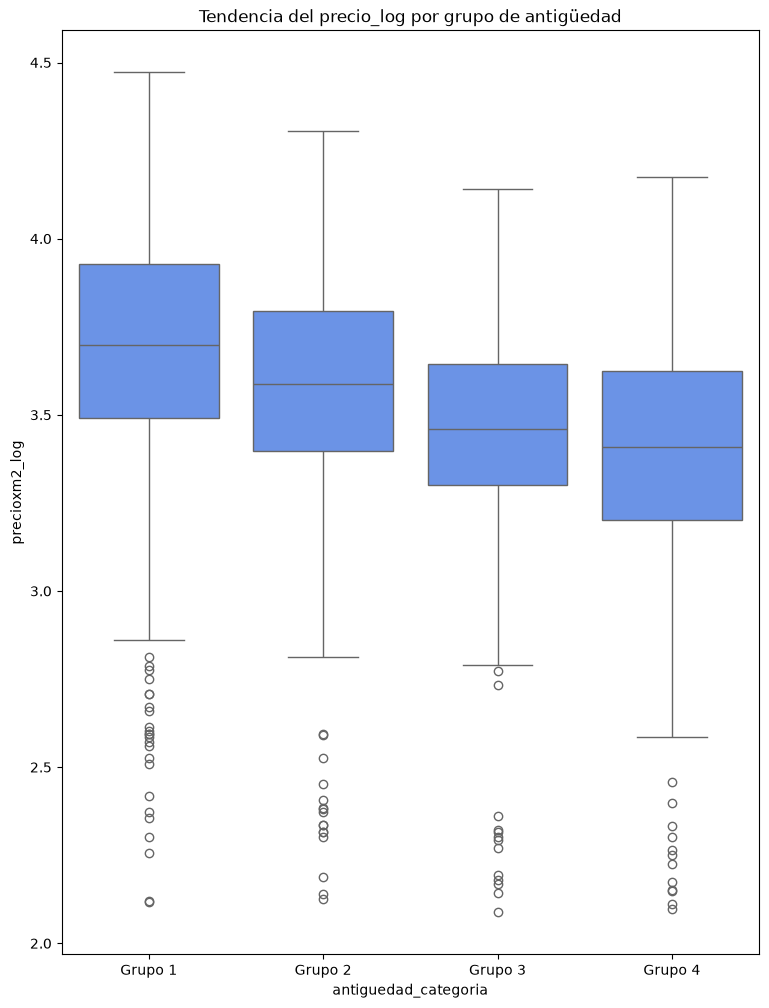

In [62]:
plt.figure(figsize=(9,12))
sns.boxplot(data=hipotesis_df, x='antiguedad_categoria', y='precioxm2_log',order=[f'Grupo {i}' for i in range(1,5)])
plt.title("Tendencia del precio_log por grupo de antigüedad")
plt.show()

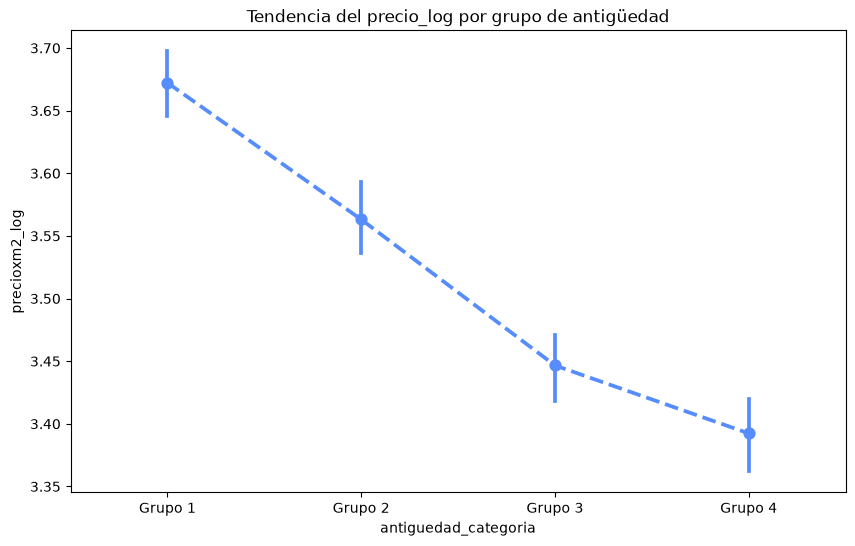

In [63]:
plt.figure(figsize=(10,6))
sns.pointplot(data=hipotesis_df,x='antiguedad_categoria',y='precioxm2_log',order=[f'Grupo {i}' for i in range(1,5)],linestyle='--',)
plt.title("Tendencia del precio_log por grupo de antigüedad")
plt.show()

In [64]:
# Eliminar filas con datos faltantes
hipotesis_df_copia.dropna(inplace=True)

# Calcular la correlación de Spearman (por defecto, el test es bilateral)
rho, p_bilateral = spearmanr(hipotesis_df_copia['antiguedad_ordinal'], hipotesis_df_copia['precioxm2_log'])

# Convertir el p-valor a test unilateral (hipótesis alternativa: correlación positiva)
p_unilateral = p_bilateral / 2 if rho < 0 else 1.0

print(f"Spearman's rho: {rho:.3f}")
print(f"p-valor (unilateral): {p_unilateral:.5f}")

Spearman's rho: -0.341
p-valor (unilateral): 0.00000


Observaciones:

- La correlación es **negativa** y significativa (**ρ = −0.341**, p ≈ 0): a mayor antigüedad, menor precio por m².

Conclusiones:

- Los departamentos más antiguos tienen un precio por metro cuadrado **menor** (ρ = −0.341), usando la transformación logarítmica para reducir la influencia de outliers.
- Puede deberse a mayores necesidades de mantenimiento o remodelación y a que su mayor área reduce el precio por m².

### Aseveracion 7:  Los departamentos más antiguos tenian mas dormitorios y baños que los recientes.

El objetivo es determinar si existe una correlación positiva entre la antigüedad de los departamentos y el numero de dormitorios + el numero de baños, es decir, si los departamentos más antiguos tienden a tener más baños y dormitorios.

- Ho: No existe una correlación significativa entre la antigüedad de los departamentos y el número de dormitorios + el número de baños ($\rho = 0$).
- H1: Existe una correlación positiva significativa entre la antigüedad de los departamentos y el número de dormitorios + el número de baños ($\rho > 0$).

Usaremos la prueba de hipótesis de spearman que es ideal para ver si existe una relación monótona, no necesariamente lineal.

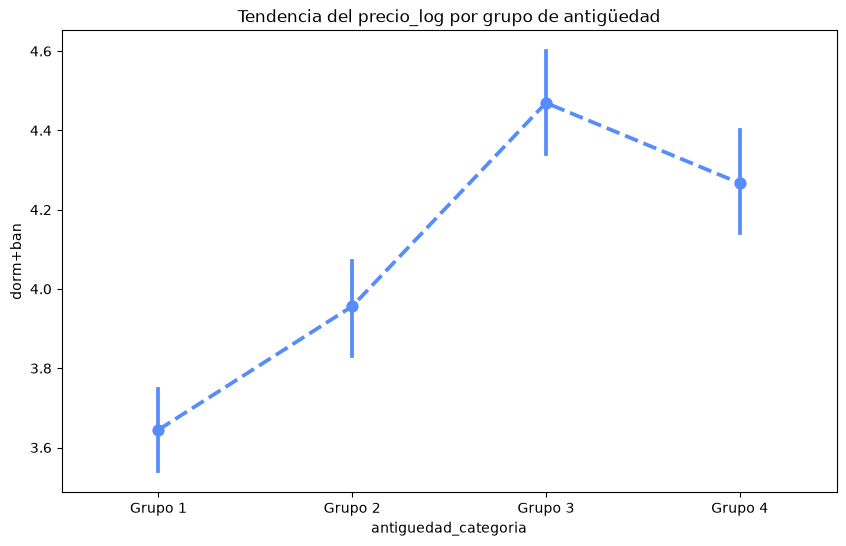

In [65]:
hipotesis_df_copia['dorm+ban'] = hipotesis_df['dormitorios']+hipotesis_df['banos']
plt.figure(figsize=(10,6))
sns.pointplot(data=hipotesis_df_copia,x='antiguedad_categoria',y='dorm+ban',order=[f'Grupo {i}' for i in range(1,5)],linestyle='--',)
plt.title("Tendencia del precio_log por grupo de antigüedad")
plt.show()

In [66]:
# Calcular correlación de Spearman (test bilateral por defecto)
rho, p_bilateral = spearmanr(hipotesis_df_copia['antiguedad_ordinal'], hipotesis_df_copia['dorm+ban'])

# Convertir a test unilateral (H₁: correlación positiva)
p_unilateral = p_bilateral / 2 if rho > 0 else 1 - p_bilateral / 2

print(f"Spearman's rho: {rho:.3f}")
print(f"p-valor (unilateral): {p_unilateral:.5f}")

Spearman's rho: 0.188
p-valor (unilateral): 0.00000


Observaciones:

- La correlación significativa respalda que existe una relación positiva entre la antigüedad y el número de baños y dormitorios.

Conclusiones:

- Existe evidencia estadistica que nos indica que los departamentos más antiguos tienen más dormitorios y baños.

### Aseveracion 8: La distribución interna de los departamentos (dormitorios y baños) influye significativamente en el precio, controlando el área.

El objetivo es determinar si, una vez controlado por el área, la configuración interna (número de dormitorios y de baños) tiene un efecto significativo en el precio de los departamentos.

- Ho: Los coeficientes de "dormitorios" y "baños" son cero cuando se controla por el área, es decir, la configuración interna no influye significativamente en el precio. (H0​:βdormitorios​=0 y βbanos​=0)
- H1: Al menos uno de los coeficientes (de "dormitorios" o "baños") es distinto de cero, lo que indica que la configuración interna tiene un efecto significativo en el precio, controlando por el área.

Utilizaremos un modelo de regresión lineal múltiple con “dormitorios”, “área” y “baños” como predictores del precio.  

In [67]:
import pandas as pd
import statsmodels.api as sm

def verificar_hipotesis_lineal(df, columnas_predictoras, columna_objetivo='precio'):
    try:
        # Datos
        X = df[columnas_predictoras]
        X = sm.add_constant(X)  # Agregar constante para la intersección
        y = df[columna_objetivo]

        # Modelo de regresión
        model = sm.OLS(y, X).fit()

        # Extraer resultados clave
        resultados = {'Intercepto': model.params['const'], 'R2': model.rsquared,
                      'R2_Ajustado': model.rsquared_adj, 'Observaciones': len(df)}

        for col in columnas_predictoras:
            resultados[f'Coef_{col}'] = model.params[col]
            resultados[f'p_{col}'] = model.pvalues[col]

        # Calcular VIF excluyendo la constante
        vif_data = [{'Variable': col, 'VIF': variance_inflation_factor(X.values, i)}
                    for i, col in enumerate(X.columns) if col != 'const']

        # Crear DataFrames para mejor visualización
        df_resultados = pd.DataFrame([resultados])
        df_vif = pd.DataFrame(vif_data)

        # Formatear números
        pd.options.display.float_format = '{:.3f}'.format

        print("\nResultados clave:")
        columnas_resultados = ['Intercepto'] + [f'Coef_{col}' for col in columnas_predictoras] + ['R2', 'R2_Ajustado', 'Observaciones']
        print(df_resultados[columnas_resultados])

        print("\nSignificancia estadística:")
        columnas_pvalores = [f'p_{col}' for col in columnas_predictoras]
        print(df_resultados[columnas_pvalores])

        print("\nMulticolinealidad (VIF):")
        print(df_vif)

        return model

    except Exception as e:
        print(f"Error en el análisis: {str(e)}")
        return None


In [68]:
# Ejecutar para cada grupo
for clase in ['clase1','clase2','clase3']:
    print(f"\n{'='*50}")
    print(f"Análisis para distrito: {clase.upper()}")
    print(f"{'='*50}")
    subset = hipotesis_df.query(f"distrito_clase=='{clase}'")
    verificar_hipotesis_lineal(subset,['area','banos','dormitorios'])


Análisis para distrito: CLASE1

Resultados clave:
   Intercepto  Coef_area  Coef_banos  Coef_dormitorios    R2  R2_Ajustado  \
0     699.459     33.414     252.135          -323.291 0.737        0.736   

   Observaciones  
0           1259  

Significancia estadística:
   p_area  p_banos  p_dormitorios
0   0.000    0.002          0.000

Multicolinealidad (VIF):
      Variable   VIF
0         area 2.132
1        banos 2.871
2  dormitorios 2.813

Análisis para distrito: CLASE2

Resultados clave:
   Intercepto  Coef_area  Coef_banos  Coef_dormitorios    R2  R2_Ajustado  \
0     536.284     23.489     298.208          -221.381 0.664        0.663   

   Observaciones  
0           1121  

Significancia estadística:
   p_area  p_banos  p_dormitorios
0   0.000    0.000          0.000

Multicolinealidad (VIF):
      Variable   VIF
0         area 1.957
1        banos 2.518
2  dormitorios 2.068

Análisis para distrito: CLASE3

Resultados clave:
   Intercepto  Coef_area  Coef_banos  Coef_dormit

Observaciones (valores de la salida anterior):

- **Dormitorios**: coeficiente negativo y significativo en las tres clases (p < 0.001). Manteniendo constantes área y baños, cada dormitorio adicional se asocia con un precio **menor** en S/ 323 (clase1), S/ 221 (clase2) y S/ 168 (clase3).
- **Área**: coeficiente positivo y significativo (p < 0.001): cada m² adicional se asocia con S/ 33 (clase1), S/ 23 (clase2) y S/ 20 (clase3) más.
- **Baños**: coeficiente positivo y significativo (p = 0.002 en clase1 y p < 0.001 en las demás): cada baño adicional se asocia con S/ 252 (clase1), S/ 298 (clase2) y S/ 195 (clase3) más.
- **R²**: 0.737 (clase1), 0.664 (clase2) y 0.619 (clase3).
- **VIF**: entre 1.6 y 2.9 en las tres clases: no hay problemas serios de multicolinealidad.

- **Interpretación**: para un mismo tamaño, más dormitorios implican ambientes más pequeños, mientras que más baños aportan comodidad. Son asociaciones condicionales a este modelo lineal; el efecto causal de un baño adicional se estima con Double ML en `notebook3_estimacion_causal.ipynb` (≈ 5.3 % del precio).

Conclusiones:
1. La configuración interna se asocia significativamente con el precio: para un área dada, más dormitorios se asocian con un precio menor.
2. Más baños se asocian con un precio mayor en los tres grupos de distritos.

In [69]:
hipotesis_df.to_csv("../csv/data_hipotesis.csv")

## CONCLUSIONES FINALES

### 1. Diferencias en precios/m² entre distritos
**Tests incluidos**:
1. **Tukey HSD** (Barranco, Miraflores, San Isidro, Lince): Barranco es significativamente más caro por m² que los otros tres; Miraflores es más caro que San Isidro y Lince; San Isidro y Lince no difieren (p = 0.43).
2. **Kruskal-Wallis** (Miraflores, San Isidro, Lince): p = 0.006, las medianas no son iguales; la diferencia la explica Miraflores.
3. **Test-t para diferencia de medias** (Lima-Top vs No-Top): Lima-Top es por lo menos 30 % más caro por m² (diferencia estimada: 36 %, p = 0.00074).

**Conclusión**:
Barranco es el distrito con el precio por m² más alto, seguido de Miraflores; San Isidro y Lince forman un tercer grupo similar. En conjunto, los distritos Lima-Top son por lo menos un 30 % más caros por m² que los demás (diferencia descriptiva, sin controlar otras características).

### 2. Efecto de la antigüedad en precio, área y distribución interna

**Tests incluidos**:
1. **Spearman** antigüedad vs precio: ρ = 0.068 (p < 0.05). Correlación positiva muy débil.
2. **Spearman** antigüedad vs área: ρ = 0.313 (p < 0.05). Los departamentos más antiguos tienen más área.
3. **Spearman** antigüedad vs precio/m²: ρ = −0.341 (p < 0.05). Los más antiguos tienen menor precio por m².
4. **Spearman** antigüedad vs dormitorios + baños: ρ = 0.188 (p < 0.05). Los más antiguos tienen algo más de dormitorios y baños.

**Conclusión unificada**:
La antigüedad se asocia con un menor precio por m², pero también con departamentos más grandes y con más ambientes; por eso el precio total apenas varía con la antigüedad.

### 3. Influencia de la distribución interna en el precio (controlando por área)

**Resultados** (regresión lineal por clase de distrito):
- **Dormitorios**: relación inversa con el precio en las tres clases; manteniendo constantes área y baños, un dormitorio más se asocia con S/ 168–323 menos.
- **Baños**: relación directa con el precio en las tres clases; manteniendo constantes área y dormitorios, un baño más se asocia con S/ 195–298 más.
- **R²** de 0.74 (clase1), 0.66 (clase2) y 0.62 (clase3); **VIF** entre 1.6 y 2.9.

**Conclusión**:
El mercado se asocia negativamente con la fragmentación del espacio (más dormitorios para un área dada) y positivamente con más baños. La versión causal de esta hipótesis (efecto de un baño adicional) se estima en `notebook3_estimacion_causal.ipynb`.

### **Resumen Final**
1. **Ubicación**: Barranco es el distrito más caro por m², seguido de Miraflores; Lima-Top es por lo menos un 30 % más caro que No-Top.
2. **Antigüedad**: se asocia con departamentos más grandes y con más ambientes, y con un menor precio por m².
3. **Distribución interna**: para un mismo área, más dormitorios se asocian con menor precio y más baños con mayor precio.

In [1]:
import pandas as pd

In [5]:
df = pd.read_csv(r"../data/data_wrangling_20250324_202229.csv")
df

,longitud,descripcion,area,banos,precio,latitud,dormitorios,fecha_publicacion,distrito,antiguedad,direccion,precision,type
0,-77.018606,Se Alquila Lindo Departamento en Barranco\n¡De...,77.0,2.0,2960.0,-12.139912,3.0,0.0,barranco,5.0,"Ca. Enrique Barrón 280, Barranco 15063, Peru",ROOFTOP,street_address
1,-77.021154,Se Alquila Departamento Duplex en Corazón de B...,96.0,2.0,2250.0,-12.139272,2.0,1.0,barranco,0.0,"Jr. Tumbes 306, Lima 15063, Peru",ROOFTOP,street_address
2,-77.023879,Se Alquila Lindo Departamento en Barranco\nSE ...,40.0,1.0,2000.0,-12.139555,1.0,1.0,barranco,8.0,"Av. el Sol Oeste 203 - 504, Barranco 15063, Peru",ROOFTOP,establishment
3,-77.017627,Departamento de 3 Habitaciones Sin Amoblar en ...,80.0,2.0,2974.0,-12.138541,3.0,1.0,barranco,10.0,"Av. República de Panamá 330, Barranco 15049, Peru",ROOFTOP,establishment
4,-77.025239,Se Alquila Lindo Departamento en La Av El Sol ...,70.0,1.0,2800.0,-12.138338,2.0,1.0,barranco,5.0,"Edificio El Sol 450, Av. el Sol Oeste 448, Bar...",ROOFTOP,street_address
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3734,-77.021154,Se Alquila Departamento Duplex en Corazón de B...,96.0,2.0,2250.0,-12.139272,2.0,3.0,surquillo,0.0,"Jr. Tumbes 306, Lima 15063, Peru",ROOFTOP,street_address
3735,-77.019023,Surquillo Minidepa Funcional 700 Soles Incluye...,35.0,1.0,700.0,-12.115735,1.0,0.0,surquillo,10.0,"VXMJ+PC2, Surquillo 15047, Peru",ROOFTOP,establishment
3736,-77.028411,Departamento Exclusivo en Alquiler en Lince 1 ...,49.0,1.0,2300.0,-12.089232,1.0,5.0,surquillo,4.0,"Orquideas 2631, Lince 15046, Peru",ROOFTOP,establishment
3737,-77.043089,NaN,NaN,NaN,NaN,-12.046689,NaN,NaN,NaN,NaN,"nan, Lima, Perú.",APPROXIMATE,colloquial_area


In [9]:
len([x for x in df.dropna(subset=["descripcion"])["descripcion"].values if "cochera" in x.lower() or "estacionamiento" in x.lower()])

2460

### https://arxiv.org/html/2206.15475v3

- https://github.com/kapumota/CC-232-Java
-  https://arxiv.org/html/2206.15475v3
- DIRECCIÓN DE ESCUELAS, VIERNES .M